# Clustering Employees – HR Analytics Case Study

## Project Aim

The objective of this study is to explore employee characteristics and discover hidden patterns in an organisation's workforce with unsupervised machine learning. Using demographic, job, career, satisfaction and attendance information on 4,410 employees, the project aims to identify distinct groups of employees with similar characteristics and working conditions.

**Approach.**
1. Inspect, merge and clean the five relational files (`general_data`, `employee_survey_data`, `manager_survey_data`, `in_time`, `out_time`), and turn the attendance logs into working-hour and absence features.
2. Explore the data (EDA) to select features for clustering, then transform and scale them.
3. Segment the employees with **K-Means**, **Hierarchical (Ward)** clustering and **DBSCAN**, without any predefined label.
4. Evaluate the models with the **Elbow method**, **Silhouette score**, **Davies–Bouldin** and **Calinski–Harabasz** indices, against random and unscaled **baselines**, and check their **stability**.
5. Profile the selected segments and use **Attrition** (never used for training) as an external check of whether the segments are meaningful, then derive recommendations for the HR department.

**Data:** [HR Analytics Case Study (Kaggle)](https://www.kaggle.com/datasets/vjchoudhary7/hr-analytics-case-study). The CSV files are expected in the `archive/` folder next to this notebook.

# Importing Libraries

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.cluster import DBSCAN, KMeans
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_samples,
                             silhouette_score)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler


import warnings
warnings.filterwarnings('ignore')

# Initial Data inspection

### Encoding check

In [2]:
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "archive"

file_paths = {
    "General": DATA_DIR / "general_data.csv",
    "Employee": DATA_DIR / "employee_survey_data.csv",
    "Manager": DATA_DIR / "manager_survey_data.csv",
    "In-time": DATA_DIR / "in_time.csv",
    "Out-time": DATA_DIR / "out_time.csv"
}

for name, path in file_paths.items():
    try:
        pd.read_csv(path, encoding="utf-8")
        print(f"{name}: UTF-8")
    except UnicodeDecodeError:
        print(f"{name}: Not UTF-8")

General: UTF-8
Employee: UTF-8
Manager: UTF-8


In-time: UTF-8


Out-time: UTF-8


### Data inspection

In [3]:
df_general = pd.read_csv(DATA_DIR / "general_data.csv")
df_employee = pd.read_csv(DATA_DIR / "employee_survey_data.csv")
df_manager = pd.read_csv(DATA_DIR / "manager_survey_data.csv")
df_inTime = pd.read_csv(DATA_DIR / "in_time.csv")
df_outTime = pd.read_csv(DATA_DIR / "out_time.csv")

In [4]:
# General
df_general.info()

df_general.describe(include='all')

print(df_general.isnull().sum())

df_general.duplicated().sum()

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      4410 non-null   int64  
 1   Attrition                4410 non-null   str    
 2   BusinessTravel           4410 non-null   str    
 3   Department               4410 non-null   str    
 4   DistanceFromHome         4410 non-null   int64  
 5   Education                4410 non-null   int64  
 6   EducationField           4410 non-null   str    
 7   EmployeeCount            4410 non-null   int64  
 8   EmployeeID               4410 non-null   int64  
 9   Gender                   4410 non-null   str    
 10  JobLevel                 4410 non-null   int64  
 11  JobRole                  4410 non-null   str    
 12  MaritalStatus            4410 non-null   str    
 13  MonthlyIncome            4410 non-null   int64  
 14  NumCompaniesWorked       4391 non-n

np.int64(0)

In [5]:
# Employee
df_employee.info()

df_employee.describe(include='all')

print(df_employee.isnull().sum())

df_employee.duplicated().sum()

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   EmployeeID               4410 non-null   int64  
 1   EnvironmentSatisfaction  4385 non-null   float64
 2   JobSatisfaction          4390 non-null   float64
 3   WorkLifeBalance          4372 non-null   float64
dtypes: float64(3), int64(1)
memory usage: 137.9 KB
EmployeeID                  0
EnvironmentSatisfaction    25
JobSatisfaction            20
WorkLifeBalance            38
dtype: int64


np.int64(0)

In [6]:
# Manager
df_manager.info()

df_manager.describe(include='all')

print(df_manager.isnull().sum())

df_manager.duplicated().sum()

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   EmployeeID         4410 non-null   int64
 1   JobInvolvement     4410 non-null   int64
 2   PerformanceRating  4410 non-null   int64
dtypes: int64(3)
memory usage: 103.5 KB
EmployeeID           0
JobInvolvement       0
PerformanceRating    0
dtype: int64


np.int64(0)

In [7]:
# In-time
df_inTime.info()

df_inTime.describe(include='all')

missing_values = df_inTime.isnull().sum()

print("Total missing values:", missing_values.sum())

print("Number of duplicate rows:", df_inTime.duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Columns: 262 entries, Unnamed: 0 to 2015-12-31
dtypes: float64(12), int64(1), str(249)
memory usage: 8.8 MB


Total missing values: 109080
Number of duplicate rows: 0


In [8]:
# Out time
df_outTime.info()

df_outTime.describe(include='all')

missing_values = df_outTime.isnull().sum()
print("Total missing values:", missing_values.sum())

print("Number of duplicate rows:", df_outTime.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Columns: 262 entries, Unnamed: 0 to 2015-12-31
dtypes: float64(12), int64(1), str(249)
memory usage: 8.8 MB


Total missing values: 109080
Number of duplicate rows: 0


 ### Identify relationships

In [9]:
datasets = {
    "General": df_general,
    "Employee": df_employee,
    "Manager": df_manager,
    "In-time": df_inTime,
    "Out-time": df_outTime
}

dataset_names = list(datasets.keys())

for i in range(len(dataset_names)):
    for j in range(i + 1, len(dataset_names)):

        name1 = dataset_names[i]
        name2 = dataset_names[j]

        common_columns = set(datasets[name1].columns) & set(datasets[name2].columns)

        print(f"{name1} - {name2}: {common_columns}")

General - Employee: {'EmployeeID'}
General - Manager: {'EmployeeID'}
General - In-time: set()
General - Out-time: set()
Employee - Manager: {'EmployeeID'}
Employee - In-time: set()
Employee - Out-time: set()
Manager - In-time: set()
Manager - Out-time: set()
In-time - Out-time: {'2015-04-08', '2015-09-25', '2015-01-22', '2015-08-11', '2015-05-21', '2015-02-18', '2015-05-27', '2015-07-28', '2015-04-06', '2015-08-21', '2015-01-21', '2015-04-29', '2015-02-12', '2015-12-10', '2015-02-25', '2015-08-07', '2015-05-22', '2015-01-23', '2015-04-28', '2015-07-08', '2015-03-27', '2015-11-18', '2015-03-26', '2015-03-30', '2015-07-03', '2015-08-05', '2015-09-16', '2015-12-31', '2015-09-18', '2015-12-03', '2015-07-02', '2015-06-22', '2015-09-15', '2015-10-09', '2015-06-23', '2015-07-24', '2015-06-25', '2015-07-01', '2015-02-24', '2015-03-12', '2015-05-11', '2015-07-21', '2015-05-13', '2015-07-13', '2015-03-19', '2015-02-02', 'Unnamed: 0', '2015-01-06', '2015-01-09', '2015-06-10', '2015-09-24', '2015-

## Data Loading and Integration

In [10]:
# Merge the three employee-level tables on the common key EmployeeID.
# validate='one_to_one' raises an error if any EmployeeID is repeated in either table.
df_final = (df_general
            .merge(df_employee, on='EmployeeID', validate='one_to_one')
            .merge(df_manager, on='EmployeeID', validate='one_to_one'))
print(df_final.shape)

(4410, 29)


In [11]:
df_final.head() # a dataframe containing complete information for each employee

,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeID,Gender,...,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,JobInvolvement,PerformanceRating
0,51,No,Travel_Rarely,Sales,6,2,Life Sciences,1,1,Female,...,1.0,6,1,0,0,3.0,4.0,2.0,3,3
1,31,Yes,Travel_Frequently,Research & Development,10,1,Life Sciences,1,2,Female,...,6.0,3,5,1,4,3.0,2.0,4.0,2,4
2,32,No,Travel_Frequently,Research & Development,17,4,Other,1,3,Male,...,5.0,2,5,0,3,2.0,2.0,1.0,3,3
3,38,No,Non-Travel,Research & Development,2,5,Life Sciences,1,4,Male,...,13.0,5,8,7,5,4.0,4.0,3.0,2,3
4,32,No,Travel_Rarely,Research & Development,10,1,Medical,1,5,Male,...,9.0,2,6,0,4,4.0,1.0,3.0,3,3


In [12]:
df_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 4410 entries, 0 to 4409
Data columns (total 29 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      4410 non-null   int64  
 1   Attrition                4410 non-null   str    
 2   BusinessTravel           4410 non-null   str    
 3   Department               4410 non-null   str    
 4   DistanceFromHome         4410 non-null   int64  
 5   Education                4410 non-null   int64  
 6   EducationField           4410 non-null   str    
 7   EmployeeCount            4410 non-null   int64  
 8   EmployeeID               4410 non-null   int64  
 9   Gender                   4410 non-null   str    
 10  JobLevel                 4410 non-null   int64  
 11  JobRole                  4410 non-null   str    
 12  MaritalStatus            4410 non-null   str    
 13  MonthlyIncome            4410 non-null   int64  
 14  NumCompaniesWorked       4391 non-n

# Data Cleaning

In [13]:
df = df_final.copy()

### Missing values check

In [14]:
print(df.isnull().sum())

Age                         0
Attrition                   0
BusinessTravel              0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeID                  0
Gender                      0
JobLevel                    0
JobRole                     0
MaritalStatus               0
MonthlyIncome               0
NumCompaniesWorked         19
Over18                      0
PercentSalaryHike           0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           9
TrainingTimesLastYear       0
YearsAtCompany              0
YearsSinceLastPromotion     0
YearsWithCurrManager        0
EnvironmentSatisfaction    25
JobSatisfaction            20
WorkLifeBalance            38
JobInvolvement              0
PerformanceRating           0
dtype: int64


In [15]:
# Exact duplicate rows and repeated IDs after the merge
print("Duplicate rows:", df.duplicated().sum())
print("Repeated EmployeeID:", df["EmployeeID"].duplicated().sum())

# Rows identical in every general_data column EXCEPT the ID
gen_cols = [c for c in df_general.columns if c != "EmployeeID"]
print("general_data rows identical to another row apart from EmployeeID:",
      df_general.duplicated(gen_cols).sum())

Duplicate rows: 0
Repeated EmployeeID: 0
general_data rows identical to another row apart from EmployeeID: 2912


**Duplicates.** There are no duplicate rows or repeated IDs, so no record is removed. However, about two thirds of the `general_data` rows are identical to another row in every column except `EmployeeID`; their survey and attendance records are different. These records are kept (each has its own survey and attendance data), and their effect on the models is analysed in the evaluation section (*Effect of replicated records*).

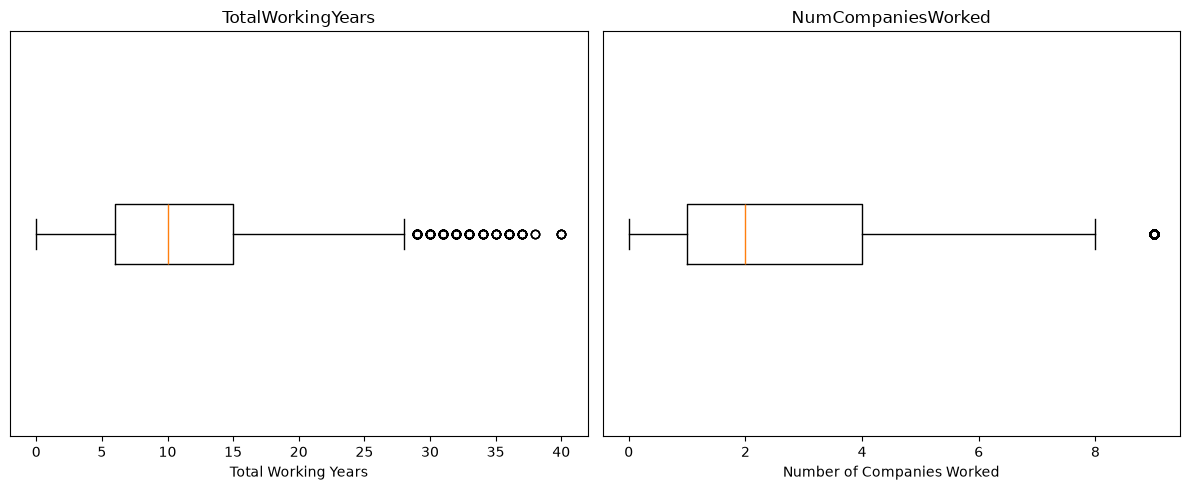

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(
    df['TotalWorkingYears'].dropna(),
    vert=False
)
axes[0].set_title('TotalWorkingYears')
axes[0].set_xlabel('Total Working Years')
axes[0].get_yaxis().set_visible(False)


axes[1].boxplot(
    df['NumCompaniesWorked'].dropna(),
    vert=False
)
axes[1].set_title('NumCompaniesWorked')
axes[1].set_xlabel('Number of Companies Worked')
axes[1].get_yaxis().set_visible(False)

plt.tight_layout()

plt.savefig(
    'latex_report/src/figures/figure1.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

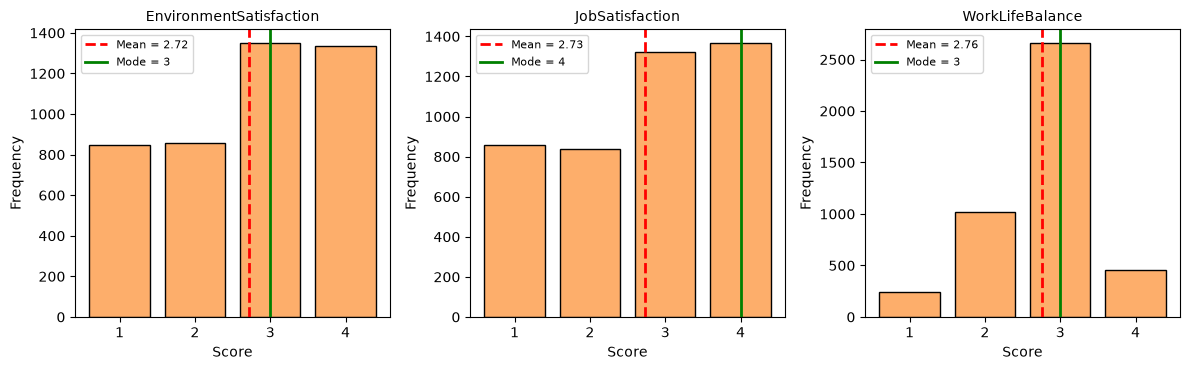

In [17]:
ORD_COLS = [
    'EnvironmentSatisfaction',
    'JobSatisfaction',
    'WorkLifeBalance'
]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))

for ax, col in zip(axes, ORD_COLS):

    data = df_employee[col].dropna()
    counts = data.value_counts().sort_index()

    ax.bar(
        counts.index.astype(int),
        counts.values,
        color="#fdae6b",
        edgecolor="black"
    )

    mean_value = data.mean()
    mode_value = data.mode().iloc[0]

    ax.axvline(
        mean_value,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Mean = {mean_value:.2f}"
    )

    ax.axvline(
        mode_value,
        color="green",
        linewidth=2,
        label=f"Mode = {int(mode_value)}"
    )

    ax.set_xticks([1, 2, 3, 4])
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("Score")
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=8)

fig.tight_layout()

plt.savefig(
    'latex_report/src/figures/figure2.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Handle missing values

In [18]:
for col in ["NumCompaniesWorked", "TotalWorkingYears"]:
    df[col] = df[col].fillna(df[col].median())

for col in ["EnvironmentSatisfaction", "JobSatisfaction", "WorkLifeBalance"]:
    df[col] = df[col].fillna(df[col].mode()[0])


### Data types and constant columns

In [19]:
int_cols = ["NumCompaniesWorked", "TotalWorkingYears",
            "EnvironmentSatisfaction", "JobSatisfaction", "WorkLifeBalance"]
df[int_cols] = df[int_cols].astype(int)

df["Attrition"] = df["Attrition"].map({"Yes": 1, "No": 0}).astype(int)

cat_cols = ["BusinessTravel", "Department", "EducationField",
            "Gender", "JobRole", "MaritalStatus"]
df[cat_cols] = df[cat_cols].astype("category")

# remove columns with constant features
const_cols = [c for c in df.columns if df[c].nunique() == 1]
df = df.drop(columns=const_cols)

### Logical consistency check
An employee cannot have spent more years at the company than in their whole career. The check is run after imputation.

In [20]:
inconsistent = df["YearsAtCompany"] > df["TotalWorkingYears"]
print(f"Employees with YearsAtCompany > TotalWorkingYears: {inconsistent.sum()} "
      f"({inconsistent.mean():.2%})")
# Show them: both cases have an imputed (median) TotalWorkingYears
df.loc[inconsistent, ["EmployeeID", "Age", "TotalWorkingYears", "YearsAtCompany"]]

Employees with YearsAtCompany > TotalWorkingYears: 2 (0.05%)


,EmployeeID,Age,TotalWorkingYears,YearsAtCompany
23,24,42,10,20
4409,4410,40,10,21


### Preparing attendance data

In [21]:
def prepare_time_df(df):
    df = df.rename(columns={'Unnamed: 0': 'EmployeeID'}).set_index('EmployeeID')
    return df.apply(pd.to_datetime, errors='coerce')

in_dt = prepare_time_df(df_inTime)
out_dt = prepare_time_df(df_outTime)
assert in_dt.shape == out_dt.shape and (in_dt.columns == out_dt.columns).all()

# holiday - no one in and out
holiday = in_dt.columns[in_dt.isna().all() & out_dt.isna().all()]
in_dt, out_dt = in_dt.drop(columns=holiday), out_dt.drop(columns=holiday)

# keep days with in and out
half = in_dt.isna() ^ out_dt.isna()
in_dt, out_dt = in_dt.mask(half), out_dt.mask(half)

# Valid duration: 0 < hours <= 24
hours = (out_dt - in_dt).apply(lambda s: s.dt.total_seconds() / 3600)
hours = hours.mask((hours <= 0) | (hours > 24))

# Aggregate per employee (absent days are skipped, not filled)
n_work = hours.shape[1]
att = pd.DataFrame({
    "AvgWorkHours": hours.mean(axis=1),
    "AbsentDays":   hours.isna().sum(axis=1),
})
att["AbsentRate"] = att["AbsentDays"] / n_work

# Employees with no valid day at all -> median
att["AvgWorkHours"] = att["AvgWorkHours"].fillna(att["AvgWorkHours"].median())
att = att.reset_index()

df_clean = df.merge(att, on="EmployeeID", how="left", validate="one_to_one")
df_clean = df_clean.reset_index(drop=True)

# Final check
assert df_clean.isnull().sum().sum() == 0
assert df_clean["EmployeeID"].is_unique

df_clean.head()

,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EmployeeID,Gender,JobLevel,...,YearsSinceLastPromotion,YearsWithCurrManager,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,JobInvolvement,PerformanceRating,AvgWorkHours,AbsentDays,AbsentRate
0,51,0,Travel_Rarely,Sales,6,2,Life Sciences,1,Female,1,...,0,0,3,4,2,3,3,7.373651,17,0.068273
1,31,1,Travel_Frequently,Research & Development,10,1,Life Sciences,2,Female,1,...,1,4,3,2,4,2,4,7.718969,13,0.052209
2,32,0,Travel_Frequently,Research & Development,17,4,Other,3,Male,4,...,0,3,2,2,1,3,3,7.013240,7,0.028112
3,38,0,Non-Travel,Research & Development,2,5,Life Sciences,4,Male,3,...,7,5,4,4,3,2,3,7.193678,14,0.056225
4,32,0,Travel_Rarely,Research & Development,10,1,Medical,5,Male,1,...,0,4,4,1,3,3,3,8.006175,4,0.016064


In [22]:
attendance_features = [
    "AvgWorkHours",
    "AbsentDays",
    "AbsentRate"
]

summary_att = pd.DataFrame({
    "Mean": att[attendance_features].mean(),
    "Std": att[attendance_features].std(),
    "Min": att[attendance_features].min(),
    "Median": att[attendance_features].median(),
    "Max": att[attendance_features].max()
})

summary_att = summary_att.round(2)

print(summary_att)

               Mean   Std   Min  Median    Max
AvgWorkHours   7.70  1.34  5.95    7.41  11.03
AbsentDays    12.73  5.50  1.00   13.00  24.00
AbsentRate     0.05  0.02  0.00    0.05   0.10


# EDA

In [23]:
RANDOM_STATE = 42
FIG_DIR = Path("latex_report/src/figures")
FIG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=0.95)

df = df_clean.set_index("EmployeeID").copy()


def save(fig, name):
    if fig.get_layout_engine() is None:      # skip when constrained layout is used
        fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    plt.show()

### DISTRIBUTIONS AND CORRELATION

#### Demographic / seniority / income / distance / workload

                       mean       std       min       50%        max  skew
Age                   36.92      9.13     18.00     36.00      60.00  0.41
MonthlyIncome      65029.31  47068.89  10090.00  49190.00  199990.00  1.37
TotalWorkingYears     11.28      7.77      0.00     10.00      40.00  1.12
YearsAtCompany         7.01      6.13      0.00      5.00      40.00  1.76
DistanceFromHome       9.19      8.11      1.00      7.00      29.00  0.96
AvgWorkHours           7.70      1.34      5.95      7.41      11.03  0.86 



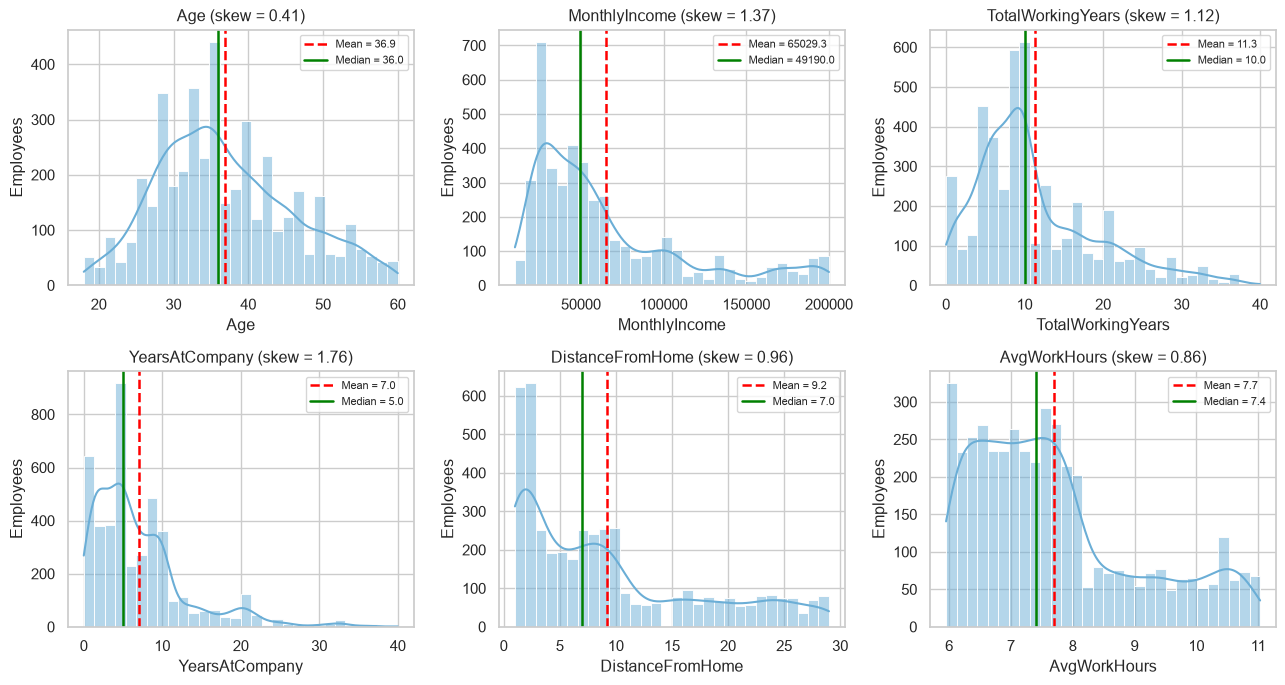

In [24]:
DIST_COLS = ["Age", "MonthlyIncome", "TotalWorkingYears",
             "YearsAtCompany", "DistanceFromHome", "AvgWorkHours"]

summary = df[DIST_COLS].describe().T[["mean", "std", "min", "50%", "max"]]
summary["skew"] = df[DIST_COLS].skew()
print(summary.round(2), "\n")

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), DIST_COLS):
    s = df[col]
    sns.histplot(s, bins=30, kde=True, color="#6baed6", edgecolor="white", ax=ax)
    ax.axvline(s.mean(), color="red", ls="--", lw=1.8, label=f"Mean = {s.mean():.1f}")
    ax.axvline(s.median(), color="green", lw=1.8, label=f"Median = {s.median():.1f}")
    ax.set_title(f"{col} (skew = {s.skew():.2f})")
    ax.set_ylabel("Employees")
    ax.legend(fontsize=8)
save(fig, "eda_dist.png")

#### Box plots (outlier view, each variable on its own scale

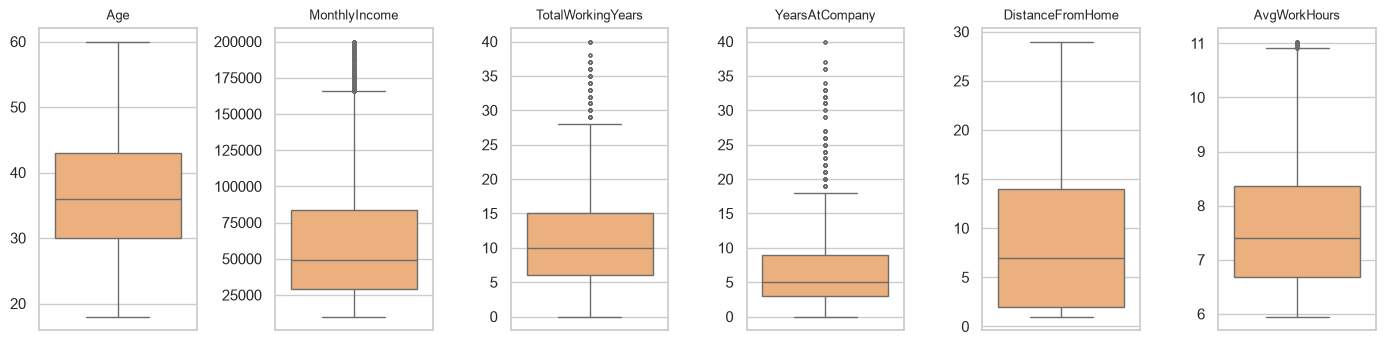

In [25]:
fig, axes = plt.subplots(1, len(DIST_COLS), figsize=(14, 3.6))
for ax, col in zip(axes, DIST_COLS):
    sns.boxplot(y=df[col], color="#fdae6b", fliersize=2, ax=ax)
    ax.set_title(col, fontsize=9)
    ax.set_ylabel("")
save(fig, "eda_boxplot.png")

#### Survey variables

   EnvironmentSatisfaction  JobSatisfaction  WorkLifeBalance  JobInvolvement
1                     19.2             19.5              5.4             5.6
2                     19.4             19.0             23.1            25.5
3                     31.2             30.0             61.2            59.0
4                     30.2             31.5             10.3             9.8 



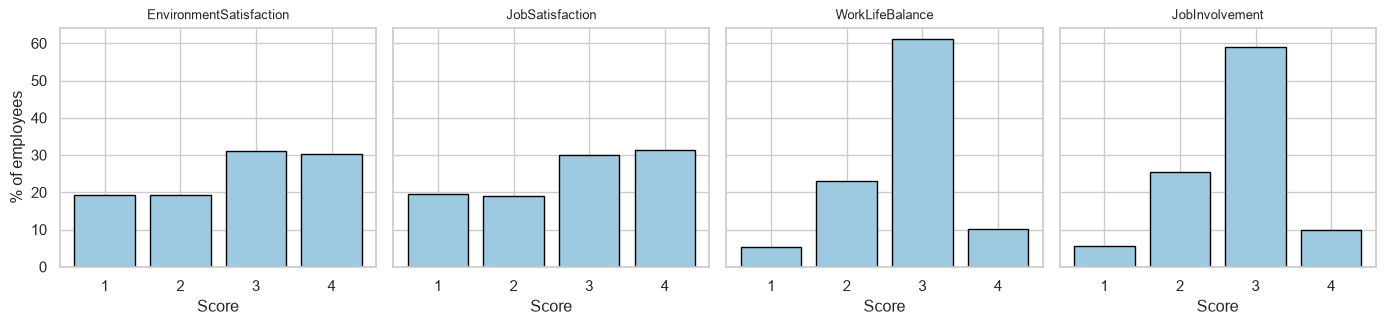

In [26]:
SURVEY = ["EnvironmentSatisfaction", "JobSatisfaction",
          "WorkLifeBalance", "JobInvolvement"]
survey_pct = (df[SURVEY].apply(lambda s: s.value_counts(normalize=True))
              .sort_index() * 100)
print(survey_pct.round(1), "\n")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
for ax, col in zip(axes, SURVEY):
    ax.bar(survey_pct.index, survey_pct[col], color="#9ecae1", edgecolor="black")
    ax.set_xticks([1, 2, 3, 4])
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("Score")
axes[0].set_ylabel("% of employees")
save(fig, "eda_survey.png")

#### Correlation

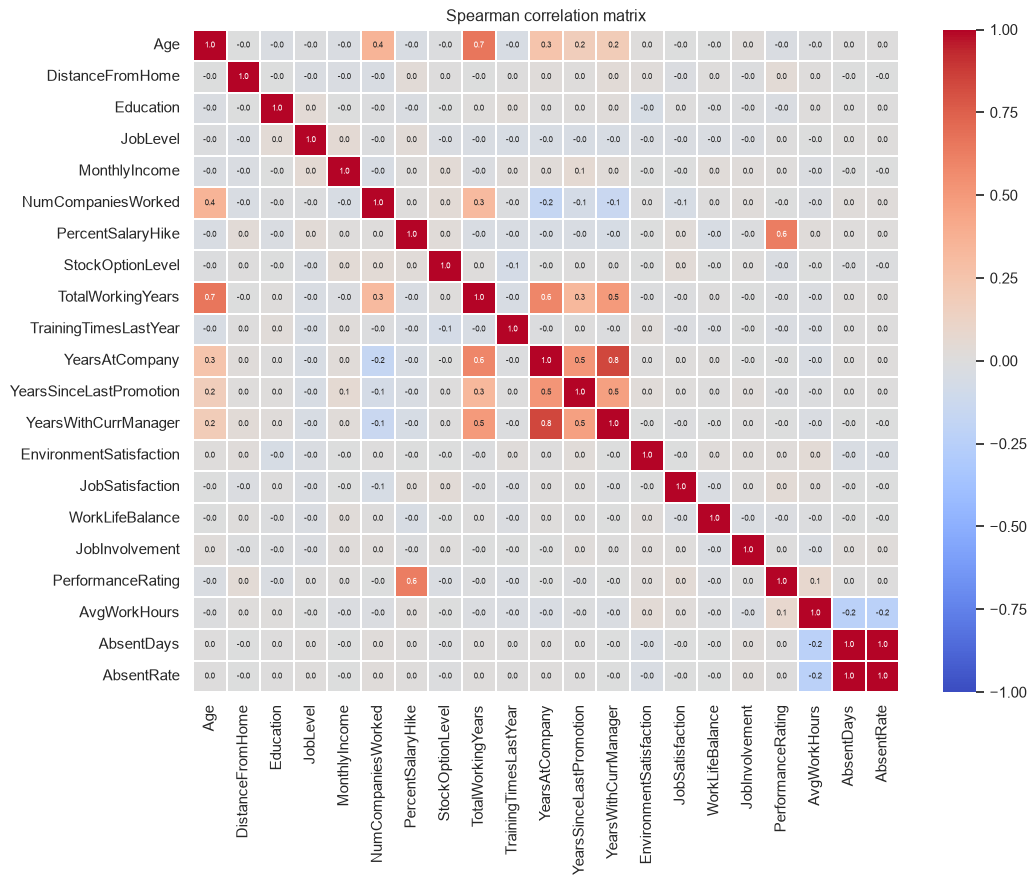

Strongly correlated pairs (|rho| >= 0.5):
        feature_1               feature_2  rho
       AbsentDays              AbsentRate 1.00
   YearsAtCompany    YearsWithCurrManager 0.84
              Age       TotalWorkingYears 0.66
PercentSalaryHike       PerformanceRating 0.63
TotalWorkingYears          YearsAtCompany 0.59
   YearsAtCompany YearsSinceLastPromotion 0.52 



In [27]:
num_cols = [c for c in df.select_dtypes("number").columns if c != "Attrition"]
corr = df[num_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True,
            fmt=".1f", annot_kws={"size": 6}, linewidths=0.3, ax=ax)
ax.set_title("Spearman correlation matrix")
save(fig, "eda_corr.png")

pairs = (corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack()
         .rename("rho").reset_index())
pairs.columns = ["feature_1", "feature_2", "rho"]
print("Strongly correlated pairs (|rho| >= 0.5):")
print(pairs[pairs["rho"].abs() >= 0.5]
      .sort_values("rho", key=abs, ascending=False).round(2).to_string(index=False), "\n")

#### Outlier detection (IQR rule)
A value is flagged as an outlier when it lies below Q1 − 1.5·IQR or above Q3 + 1.5·IQR. The table lists the variables with outliers and the decision taken for each.

In [28]:
NUM_EDA = [c for c in df.select_dtypes("number").columns
           if c not in ("Attrition", "AbsentDays")]
q1, q3 = df[NUM_EDA].quantile(0.25), df[NUM_EDA].quantile(0.75)
iqr = q3 - q1
is_out = (df[NUM_EDA] < q1 - 1.5 * iqr) | (df[NUM_EDA] > q3 + 1.5 * iqr)
outliers = pd.DataFrame({"outliers": is_out.sum(), "% of employees": is_out.mean() * 100,
                         "upper fence": q3 + 1.5 * iqr})
outliers = outliers[outliers["outliers"] > 0].sort_values("outliers", ascending=False)

DECISION = {
    "MonthlyIncome": "keep, log1p (real high salaries)",
    "YearsAtCompany": "keep, log1p (long tenure is real)",
    "YearsSinceLastPromotion": "keep, log1p (stagnation is a target profile)",
    "TotalWorkingYears": "keep, log1p",
    "AvgWorkHours": "keep (long hours = overtime profile of interest)",
    "NumCompaniesWorked": "keep (not a clustering feature)",
    "YearsWithCurrManager": "keep (not a clustering feature)",
    "TrainingTimesLastYear": "keep (discrete 0-6, not a clustering feature)",
    "PerformanceRating": "keep (only values 3/4; '4' flagged by the rule)",
    "StockOptionLevel": "keep (discrete 0-3, not a clustering feature)",
}
outliers["decision"] = outliers.index.map(DECISION)
outliers.round(1)

,outliers,% of employees,upper fence,decision
TrainingTimesLastYear,714,16.2,4.5,"keep (discrete 0-6, not a clustering feature)"
PerformanceRating,678,15.4,3.0,keep (only values 3/4; '4' flagged by the rule)
MonthlyIncome,342,7.8,165835.0,"keep, log1p (real high salaries)"
YearsSinceLastPromotion,321,7.3,7.5,"keep, log1p (stagnation is a target profile)"
YearsAtCompany,312,7.1,18.0,"keep, log1p (long tenure is real)"
StockOptionLevel,255,5.8,2.5,"keep (discrete 0-3, not a clustering feature)"
TotalWorkingYears,189,4.3,28.5,"keep, log1p"
NumCompaniesWorked,156,3.5,8.5,keep (not a clustering feature)
YearsWithCurrManager,42,1.0,14.5,keep (not a clustering feature)
AvgWorkHours,38,0.9,10.9,keep (long hours = overtime profile of interest)


**Interpretation.** No value is impossible (no negative tenure, no working day above 24 hours), so no outlier is an error. The flagged values are real but extreme employees – senior staff with high pay or long tenure, and people working long days. Removing them would delete exactly the profiles HR is interested in, so they are **kept**; the four skewed clustering features are log-transformed instead (next section) so that the extremes do not dominate the distances. For discrete variables such as `PerformanceRating` or `TrainingTimesLastYear` the IQR rule flags whole categories, which are not outliers in a meaningful sense.

#### Hypothesis tests: leavers vs. stayers
Before clustering we test which variables differ between employees who left and those who stayed (H0: same distribution). The Mann–Whitney U test is used for numeric/ordinal variables (no normality assumption) and the chi-square test of independence for categorical variables. `Attrition` is used here only to understand the data; it is not a clustering feature.

In [29]:
from scipy.stats import mannwhitneyu, chi2_contingency

left, stayed = df[df["Attrition"] == 1], df[df["Attrition"] == 0]
test_rows = []
for c in [c for c in NUM_EDA if c != "EmployeeID"]:
    test_rows.append({"variable": c, "test": "Mann-Whitney U",
                      "leavers (median)": left[c].median(), "stayers (median)": stayed[c].median(),
                      "p_value": mannwhitneyu(left[c], stayed[c]).pvalue})
for c in ["BusinessTravel", "MaritalStatus", "Department", "JobRole", "EducationField", "Gender"]:
    test_rows.append({"variable": c, "test": "Chi-square",
                      "p_value": chi2_contingency(pd.crosstab(df[c], df["Attrition"]))[1]})
tests = pd.DataFrame(test_rows).set_index("variable").sort_values("p_value")
tests["significant (p < 0.05)"] = tests["p_value"] < 0.05
tests["p_value"] = tests["p_value"].map("{:.1e}".format)
tests.round(2).fillna("")

,test,leavers (median),stayers (median),p_value,significant (p < 0.05)
variable,,,,,
TotalWorkingYears,Mann-Whitney U,7.0,10.0,2.4e-39,True
AvgWorkHours,Mann-Whitney U,8.19,7.31,8.0e-37,True
YearsAtCompany,Mann-Whitney U,3.0,6.0,1.2e-36,True
YearsWithCurrManager,Mann-Whitney U,2.0,3.0,2.5e-31,True
MaritalStatus,Chi-square,,,8.5e-31,True
Age,Mann-Whitney U,32.0,36.0,6.0e-30,True
BusinessTravel,Chi-square,,,1.8e-16,True
JobSatisfaction,Mann-Whitney U,3.0,3.0,6.4e-12,True
EnvironmentSatisfaction,Mann-Whitney U,3.0,3.0,3.0e-10,True


**Interpretation.**
- The strongest differences concern **tenure** (`TotalWorkingYears`, `YearsAtCompany`, `YearsWithCurrManager`, `Age`): leavers are younger and newer. **Working hours** are just as important: leavers work about 8.2 hours per day against 7.3.
- **Satisfaction** scores (job, environment, work-life balance) are also significantly lower for leavers, as are business travel, marital status (singles) and department.
- **Income, job level, distance from home, education and gender do not differ** (p > 0.05).
- These tests support including tenure, workload and satisfaction in the clustering features. Distance from home is not linked to attrition but is kept to describe the commute dimension.
- Caveat: many employee records are replicated three times in this dataset (see *Effect of replicated records* in the evaluation), so the effective sample is smaller than 4,410 and the p-values are optimistic. The large effects remain significant either way.

### FEATURE SELECTION

In [30]:
FEATURE_GROUPS = {
    "Seniority & pay": ["MonthlyIncome", "JobLevel", "TotalWorkingYears",
                        "YearsAtCompany", "YearsSinceLastPromotion"],
    "Workload & attendance": ["AvgWorkHours", "AbsentRate"],
    "Satisfaction & engagement": ["EnvironmentSatisfaction", "JobSatisfaction",
                                  "WorkLifeBalance", "JobInvolvement"],
    "Commute & travel": ["DistanceFromHome", "BusinessTravel"],
}
FEATURES = [c for cols in FEATURE_GROUPS.values() for c in cols]

# Dropped variables and the reason (for the report)
DROPPED = {
    "EmployeeID / Attrition": "identifier / external-validation label",
    "AbsentDays": "duplicate of AbsentRate (rho = 1.0)",
    "YearsWithCurrManager": "redundant with YearsAtCompany",
    "Age": "redundant with TotalWorkingYears",
    "PerformanceRating": "only values 3/4 (85/15 split), tied to PercentSalaryHike",
    "PercentSalaryHike": "tied to PerformanceRating, no link to the segmentation goal",
    "Education, NumCompaniesWorked, StockOptionLevel, TrainingTimesLastYear":
        "not related to the workload / satisfaction / seniority goals",
    "Department, JobRole, EducationField, MaritalStatus, Gender":
        "nominal: kept for profiling clusters after clustering",
}
print(f"{len(FEATURES)} selected features:")
for g, cols in FEATURE_GROUPS.items():
    print(f"  {g}: {cols}")
print()

13 selected features:
  Seniority & pay: ['MonthlyIncome', 'JobLevel', 'TotalWorkingYears', 'YearsAtCompany', 'YearsSinceLastPromotion']
  Workload & attendance: ['AvgWorkHours', 'AbsentRate']
  Satisfaction & engagement: ['EnvironmentSatisfaction', 'JobSatisfaction', 'WorkLifeBalance', 'JobInvolvement']
  Commute & travel: ['DistanceFromHome', 'BusinessTravel']



**Note on the satisfaction group.** The four survey scores are kept because describing satisfaction is part of the project goal, and the hypothesis tests above show that they differ between leavers and stayers. They are, however, almost uncorrelated with all other features, so they may add little *group structure*. This is tested explicitly in the sensitivity analysis of the evaluation section (removing the group barely changes the clusters).

### PREPROCESSING FOR CLUSTERING

#### Encoding

In [31]:
df["BusinessTravel"] = (df["BusinessTravel"].astype(str)
                        .map({"Non-Travel": 0, "Travel_Rarely": 1,
                              "Travel_Frequently": 2}).astype(int))

# One-hot encoding: nominal variables (no order). Not used as clustering
# input; kept to profile clusters later.
NOMINAL = ["Department", "JobRole", "EducationField", "MaritalStatus", "Gender"]
X_nominal = pd.get_dummies(df[NOMINAL].astype(str), dtype=int)

#### Skewness

Skewness before / after log1p:
                         before  after_log1p
MonthlyIncome              1.37         0.29
TotalWorkingYears          1.12        -0.62
YearsAtCompany             1.76        -0.21
YearsSinceLastPromotion    1.98         0.72 



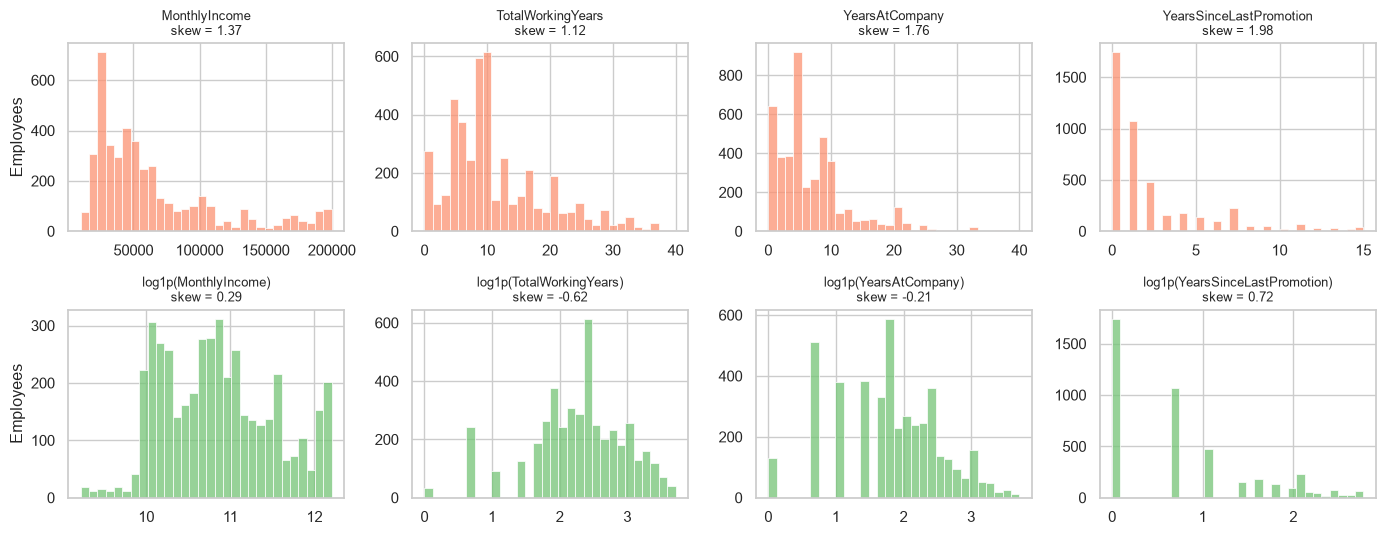

In [32]:
CONTINUOUS = ["MonthlyIncome", "TotalWorkingYears", "YearsAtCompany",
              "YearsSinceLastPromotion", "AvgWorkHours", "AbsentRate",
              "DistanceFromHome"]
SKEWED = [c for c in CONTINUOUS if df[c].skew() > 1]

X_raw = df[FEATURES].astype(float).copy()
X_log = X_raw.copy()
X_log[SKEWED] = np.log1p(X_log[SKEWED])

skew_table = pd.DataFrame({"before": X_raw[SKEWED].skew(),
                           "after_log1p": X_log[SKEWED].skew()})
print("Skewness before / after log1p:")
print(skew_table.round(2), "\n")

fig, axes = plt.subplots(2, len(SKEWED), figsize=(14, 5.5))
for j, col in enumerate(SKEWED):
    sns.histplot(X_raw[col], bins=30, color="#fc9272", ax=axes[0, j])
    axes[0, j].set_title(f"{col}\nskew = {X_raw[col].skew():.2f}", fontsize=9)
    sns.histplot(X_log[col], bins=30, color="#74c476", ax=axes[1, j])
    axes[1, j].set_title(f"log1p({col})\nskew = {X_log[col].skew():.2f}", fontsize=9)
    for i in (0, 1):
        axes[i, j].set_xlabel("")
        axes[i, j].set_ylabel("Employees" if j == 0 else "")
save(fig, "prep_skew.png")

#### Scaling

In [33]:
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X_log), index=X_log.index, columns=FEATURES)
print("Std of raw features (MonthlyIncome dominates distance-based models):")
print(X_raw.std().round(2).sort_values(ascending=False).head(4).to_string(), "\n")
assert X.isnull().sum().sum() == 0

Std of raw features (MonthlyIncome dominates distance-based models):
MonthlyIncome        47068.89
DistanceFromHome         8.11
TotalWorkingYears        7.77
YearsAtCompany           6.13 



#### Sanity check: effect of scaling and encoding on K-Means

In [34]:
def kmeans_silhouette(M_fit, M_score=X, ks=range(2, 7)):
    """Fit K-Means on M_fit, but always score the labels in the SAME space (the
    scaled matrix X). Scoring each matrix in its own space is not comparable:
    on raw data the distance is almost only MonthlyIncome, so the silhouette
    looks high (~0.7) although the clusters only cut income into bands."""
    return {k: round(silhouette_score(
        M_score, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(M_fit)), 3)
        for k in ks}

check = pd.DataFrame({
    "raw (no scaling)": kmeans_silhouette(X_raw),
    "log + StandardScaler": kmeans_silhouette(X),
    "scaled + one-hot nominal": kmeans_silhouette(pd.concat([X, X_nominal], axis=1)),
}).T
print("K-Means silhouette by k (all scored in the scaled 13-feature space):")
print(check.to_string(), "\n")

# For reference: raw-data silhouette measured in its own (income-dominated) space
own = silhouette_score(X_raw, KMeans(2, n_init=10, random_state=RANDOM_STATE).fit_predict(X_raw))
print(f"Raw K-Means (k=2) scored in its own raw space: {own:.3f}  <- misleading, income only")

K-Means silhouette by k (all scored in the scaled 13-feature space):
                              2      3      4      5      6
raw (no scaling)          0.066  0.026  0.014  0.010  0.003
log + StandardScaler      0.103  0.082  0.078  0.082  0.080
scaled + one-hot nominal  0.103  0.081  0.078  0.082  0.080 

Raw K-Means (k=2) scored in its own raw space: 0.708  <- misleading, income only


### DIMENSIONALITY REDUCTION (visualisation)

#### PCA

PC1 = 15.8%, PC2 = 9.8%, PC1+PC2 = 25.6%
Components needed for 90% variance: 11 of 13



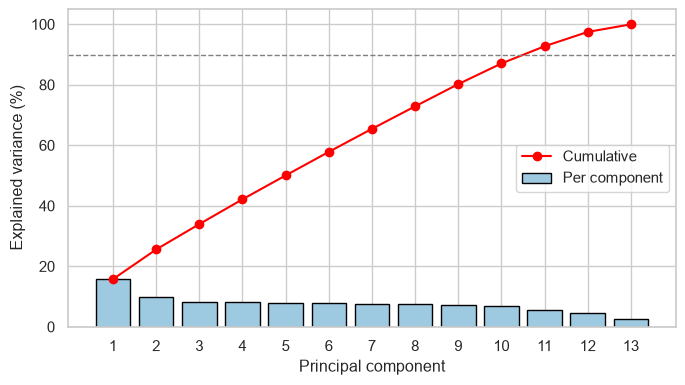

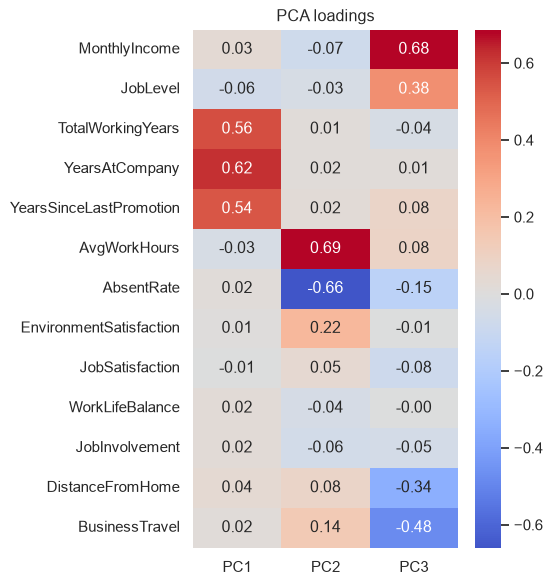

In [35]:
pca = PCA(random_state=RANDOM_STATE).fit(X)
evr = pca.explained_variance_ratio_
cum = evr.cumsum()
n90 = int(np.argmax(cum >= 0.90)) + 1
print(f"PC1 = {evr[0]:.1%}, PC2 = {evr[1]:.1%}, PC1+PC2 = {cum[1]:.1%}")
print(f"Components needed for 90% variance: {n90} of {len(FEATURES)}\n")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(evr) + 1), evr * 100, color="#9ecae1", edgecolor="black",
       label="Per component")
ax.plot(range(1, len(evr) + 1), cum * 100, "o-", color="red", label="Cumulative")
ax.axhline(90, color="gray", ls="--", lw=1)
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance (%)")
ax.set_xticks(range(1, len(evr) + 1))
ax.legend()
save(fig, "pca_scree.png")

X_pca = pd.DataFrame(pca.transform(X), index=X.index,
                     columns=[f"PC{i + 1}" for i in range(len(FEATURES))])

loadings = pd.DataFrame(pca.components_[:3].T, index=FEATURES,
                        columns=["PC1", "PC2", "PC3"])
fig, ax = plt.subplots(figsize=(5.5, 6))
sns.heatmap(loadings, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("PCA loadings")
save(fig, "pca_loadings.png")

#### PCA 2D vs t-SNE 2D

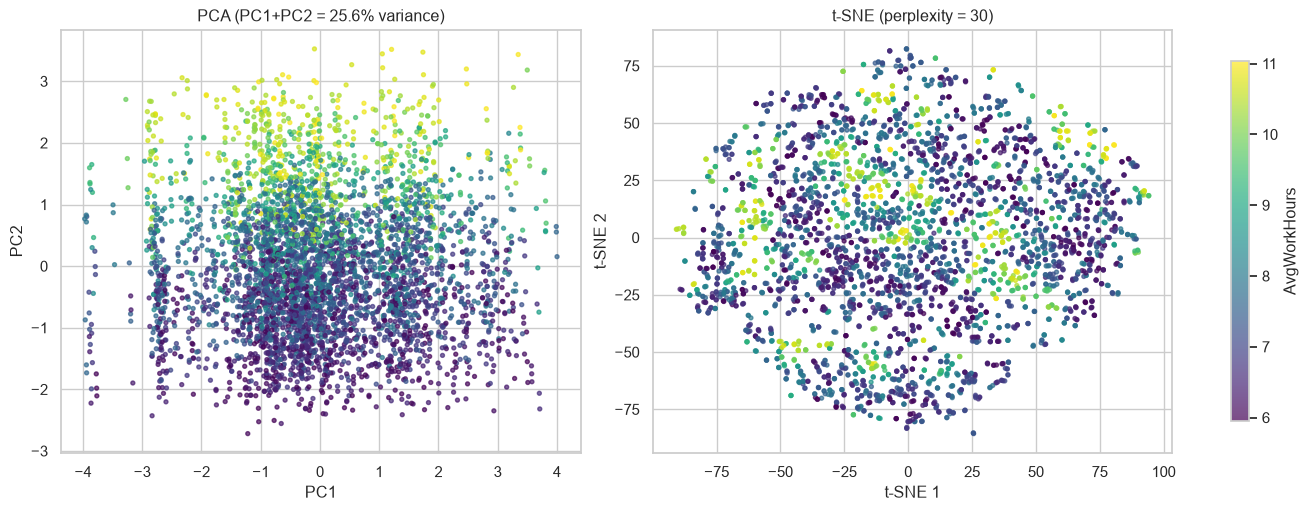

In [36]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
            random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X)

COLOR_BY = "AvgWorkHours"   # colour only for visual reading; not used by the models
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for ax, (xy, title) in zip(axes, [
        (X_pca[["PC1", "PC2"]].values, f"PCA (PC1+PC2 = {cum[1]:.1%} variance)"),
        (X_tsne, "t-SNE (perplexity = 30)")]):
    sc = ax.scatter(xy[:, 0], xy[:, 1], c=df[COLOR_BY], cmap="viridis", s=8, alpha=0.7)
    ax.set_title(title)
fig.colorbar(sc, ax=axes, label=COLOR_BY, shrink=0.85)
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
axes[1].set_xlabel("t-SNE 1"); axes[1].set_ylabel("t-SNE 2")
save(fig, "embedding_2d.png")

In [37]:
X.head()

,MonthlyIncome,JobLevel,TotalWorkingYears,YearsAtCompany,YearsSinceLastPromotion,AvgWorkHours,AbsentRate,EnvironmentSatisfaction,JobSatisfaction,WorkLifeBalance,JobInvolvement,DistanceFromHome,BusinessTravel
EmployeeID,,,,,,,,,,,,,
1,1.398738,-0.961486,-2.294803,-1.478408,-0.973342,-0.244123,0.775066,0.252200,1.148864,-1.085336,0.379672,-0.393938,-0.162399
2,-0.319624,-0.961486,-0.499422,-0.026394,-0.117271,0.013564,0.048210,0.252200,-0.666107,1.757749,-1.026167,0.099639,1.717339
3,1.982468,1.749610,-0.720341,-0.026394,-0.973342,-0.513073,-1.042074,-0.665460,-0.666107,-2.506879,0.379672,0.963398,1.717339
4,0.713645,0.845911,0.493953,0.509502,1.594870,-0.378424,0.229924,1.169861,1.148864,0.336206,-1.026167,-0.887515,-2.042138
5,-1.195006,-0.961486,0.011742,0.177344,-0.973342,0.227886,-1.587216,1.169861,-1.573592,0.336206,0.379672,0.099639,-0.162399


# CLUSTERING MODELS

In [38]:
A = X.values
K_RANGE = range(2, 11)


def scores(M, lab):
    """Three internal validity indices for one clustering."""
    return {"silhouette": silhouette_score(M, lab),
            "davies_bouldin": davies_bouldin_score(M, lab),
            "calinski_harabasz": calinski_harabasz_score(M, lab)}

## K-MEANS: Elbow, Silhouette, stability

K-Means model selection:
      inertia  silhouette  davies_bouldin  calinski_harabasz  stability_ARI  inertia_drop_%
k                                                                                          
2   51464.943       0.103           2.716            502.345          0.947             NaN
3   48751.226       0.081           3.046            387.755          0.851           5.273
4   46659.267       0.078           2.848            335.878          0.623           4.291
5   44709.186       0.082           2.666            310.869          0.816           4.179
6   43144.688       0.080           2.570            289.595          0.704           3.499
7   41836.795       0.075           2.458            271.757          0.787           3.031
8   40806.339       0.078           2.338            254.644          0.683           2.463
9   39982.384       0.074           2.251            238.690          0.602           2.019
10  39297.796       0.066           2.413            22

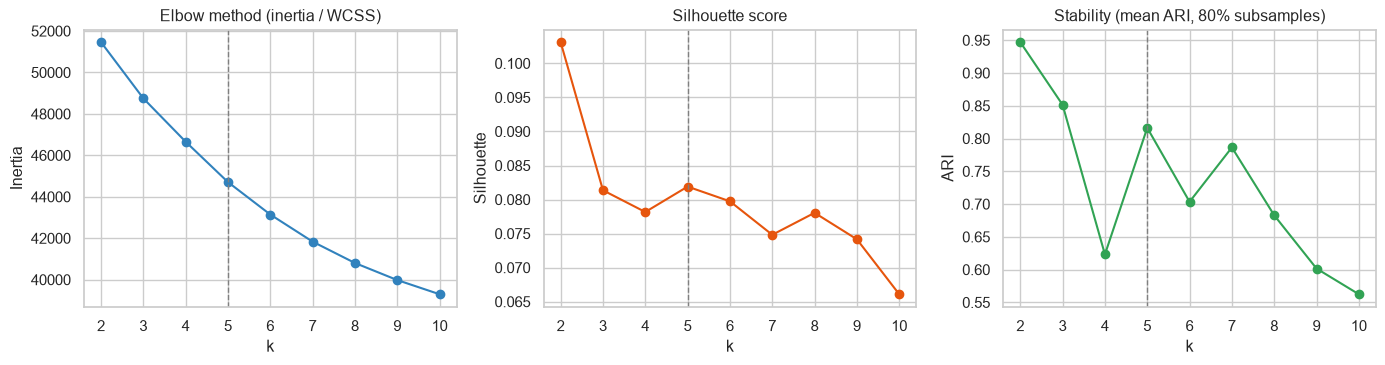

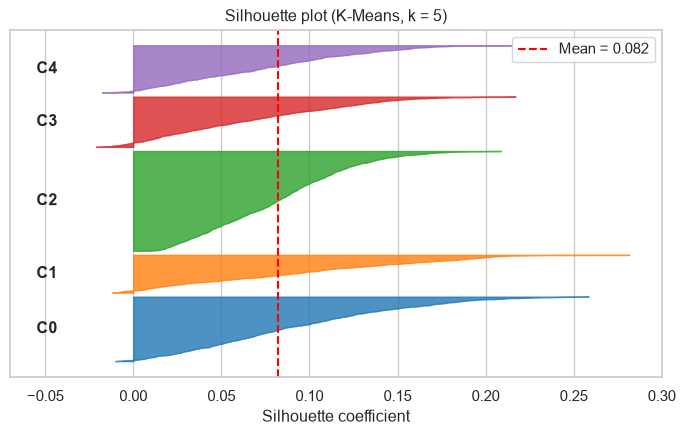

Cluster sizes (K-Means): [949, 556, 1469, 740, 696] | share of negative silhouette: 3.2%



In [39]:
def kmeans_stability(M, k, n_runs=10, frac=0.8):
    """Mean ARI between K-Means fitted on random 80% subsamples
    (every model then labels all employees)."""
    rng = np.random.RandomState(RANDOM_STATE)
    labs = []
    for b in range(n_runs):
        idx = rng.choice(len(M), int(frac * len(M)), replace=False)
        labs.append(KMeans(k, n_init=10, random_state=b).fit(M[idx]).predict(M))
    return np.mean([adjusted_rand_score(labs[i], labs[j])
                    for i in range(n_runs) for j in range(i + 1, n_runs)])


rows = []
for k in K_RANGE:
    km = KMeans(k, n_init=20, random_state=RANDOM_STATE).fit(A)
    rows.append({"k": k, "inertia": km.inertia_, **scores(A, km.labels_),
                 "stability_ARI": kmeans_stability(A, k)})
km_table = pd.DataFrame(rows).set_index("k")
km_table["inertia_drop_%"] = -km_table["inertia"].pct_change() * 100
print("K-Means model selection:")
print(km_table.round(3).to_string(), "\n")

# Choice of K: k = 2 only separates tenure (see Report), so the search starts
# at k = 3 and takes the highest silhouette in 3..8.
K_FINAL = int(km_table.loc[3:8, "silhouette"].idxmax())
print(f"K_FINAL = {K_FINAL}\n")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(km_table.index, km_table["inertia"], "o-", color="#3182bd")
axes[0].set(title="Elbow method (inertia / WCSS)", xlabel="k", ylabel="Inertia")
axes[1].plot(km_table.index, km_table["silhouette"], "o-", color="#e6550d")
axes[1].set(title="Silhouette score", xlabel="k", ylabel="Silhouette")
axes[2].plot(km_table.index, km_table["stability_ARI"], "o-", color="#31a354")
axes[2].set(title="Stability (mean ARI, 80% subsamples)", xlabel="k", ylabel="ARI")
for ax in axes:
    ax.axvline(K_FINAL, color="gray", ls="--", lw=1)
    ax.set_xticks(list(K_RANGE))
save(fig, "km_selection.png")

km = KMeans(K_FINAL, n_init=20, random_state=RANDOM_STATE).fit(A)
labels = pd.DataFrame(index=X.index)
labels["KMeans"] = km.labels_

# Silhouette plot of every employee for the chosen K
sil = silhouette_samples(A, km.labels_)
fig, ax = plt.subplots(figsize=(7, 4.5))
y0 = 0
for c in range(K_FINAL):
    s = np.sort(sil[km.labels_ == c])
    ax.fill_betweenx(np.arange(y0, y0 + len(s)), 0, s, alpha=0.8,
                     color=plt.cm.tab10(c))
    ax.text(-0.055, y0 + len(s) / 2, f"C{c}", va="center", fontweight="bold")
    y0 += len(s) + 60
ax.axvline(sil.mean(), color="red", ls="--", label=f"Mean = {sil.mean():.3f}")
ax.set(title=f"Silhouette plot (K-Means, k = {K_FINAL})",
       xlabel="Silhouette coefficient", yticks=[], xlim=(-0.07, 0.3))
ax.legend()
save(fig, "km_silhouette_plot.png")
print("Cluster sizes (K-Means):", np.bincount(km.labels_).tolist(),
      "| share of negative silhouette: "
      f"{(sil < 0).mean():.1%}\n")

## HIERARCHICAL CLUSTERING (Ward) + DENDROGRAM

Ward model selection:
    silhouette  davies_bouldin  calinski_harabasz
k                                                
2        0.073           2.976            319.346
3        0.062           3.378            263.481
4        0.045           3.543            235.781
5        0.047           3.240            218.631
6        0.048           3.060            204.597
7        0.047           2.976            192.632
8        0.044           2.989            184.611
9        0.043           2.861            177.717
10       0.038           2.711            169.453 



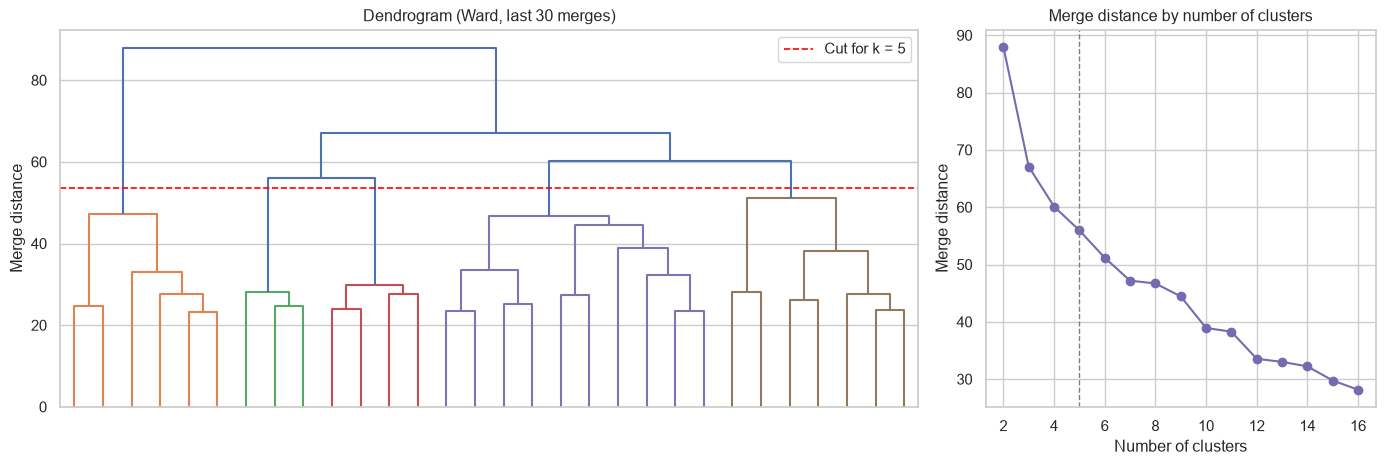

ARI between K-Means and Ward (k = 5): 0.344
Cluster sizes (Ward): [989, 451, 434, 1576, 960] 



In [40]:
Z = linkage(A, method="ward")

ward_rows = []
for k in K_RANGE:
    lab = fcluster(Z, k, criterion="maxclust") - 1
    ward_rows.append({"k": k, **scores(A, lab)})
ward_table = pd.DataFrame(ward_rows).set_index("k")
print("Ward model selection:")
print(ward_table.round(3).to_string(), "\n")

labels["Ward"] = fcluster(Z, K_FINAL, criterion="maxclust") - 1
cut_height = (Z[-(K_FINAL - 1), 2] + Z[-K_FINAL, 2]) / 2   # between k and k-1 merges

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=cut_height,
           no_labels=True, ax=axes[0])
axes[0].axhline(cut_height, color="red", ls="--", lw=1.2,
                label=f"Cut for k = {K_FINAL}")
axes[0].set(title="Dendrogram (Ward, last 30 merges)", ylabel="Merge distance")
axes[0].legend()
heights = Z[-15:, 2][::-1]
axes[1].plot(range(2, 17), heights, "o-", color="#756bb1")
axes[1].axvline(K_FINAL, color="gray", ls="--", lw=1)
axes[1].set(title="Merge distance by number of clusters", xlabel="Number of clusters",
            ylabel="Merge distance")
save(fig, "dendrogram_ward.png")

ari_km_ward = adjusted_rand_score(labels["KMeans"], labels["Ward"])
print(f"ARI between K-Means and Ward (k = {K_FINAL}): {ari_km_ward:.3f}")
print("Cluster sizes (Ward):", np.bincount(labels["Ward"]).tolist(), "\n")

## DBSCAN: density clusters and anomalies

DBSCAN sensitivity (min_samples = 26):
     clusters  noise  noise_%
eps                          
2.6         1    927     21.0
2.8         1    348      7.9
3.0         1    105      2.4
3.2         1     33      0.7
3.4         1      4      0.1 



DBSCAN (eps = 3.0): 1 cluster(s), 105 anomalies (2.4%)


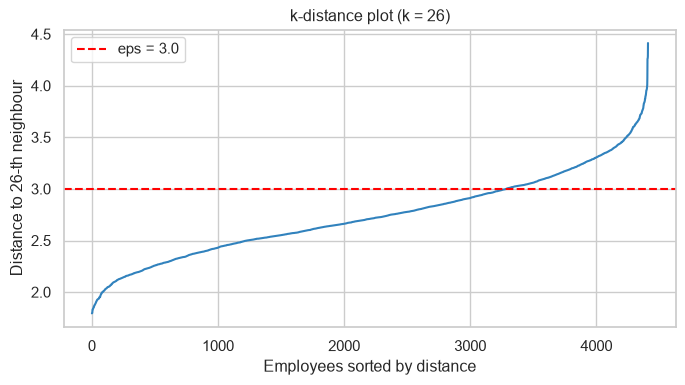

Mean z-score of anomalies:
WorkLifeBalance           -0.87
YearsAtCompany            -0.55
JobInvolvement            -0.48
TotalWorkingYears         -0.40
YearsSinceLastPromotion   -0.40
AbsentRate                -0.20
BusinessTravel            -0.11
JobSatisfaction            0.05
EnvironmentSatisfaction    0.12
DistanceFromHome           0.65
MonthlyIncome              0.69
AvgWorkHours               0.87
JobLevel                   0.94
Attrition rate: anomalies 36.2% vs rest 15.6%



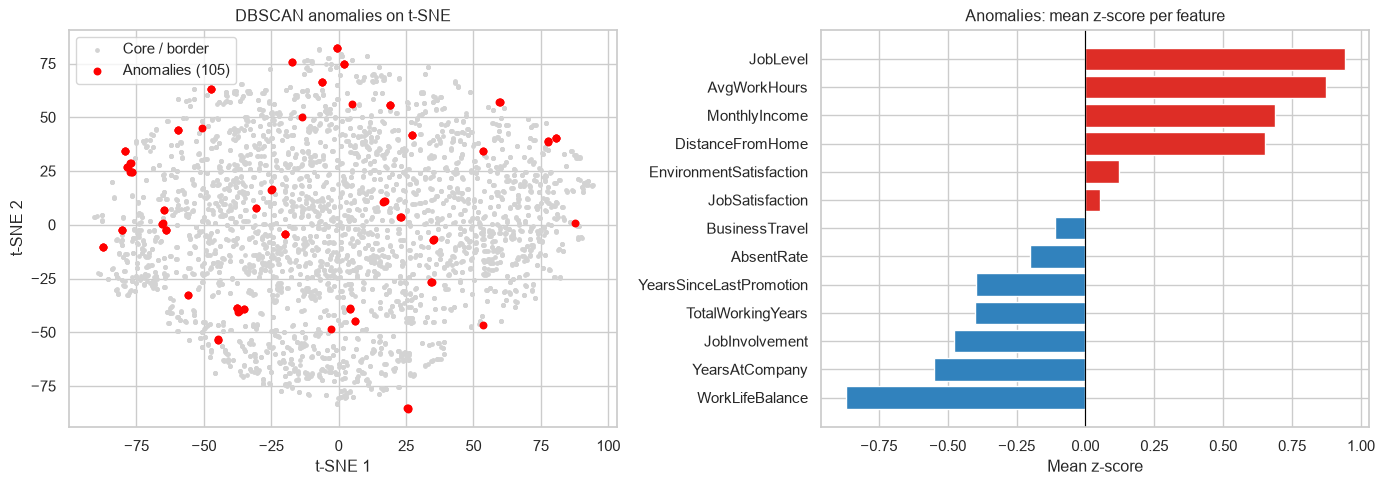

In [41]:
MIN_SAMPLES = 2 * A.shape[1]          # common rule: 2 x number of features
kdist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(A)
                .kneighbors(A)[0][:, -1])

sens = []
for eps in (2.6, 2.8, 3.0, 3.2, 3.4):
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(A)
    sens.append({"eps": eps, "clusters": len(set(lab) - {-1}),
                 "noise": int((lab == -1).sum()),
                 "noise_%": (lab == -1).mean() * 100})
sens = pd.DataFrame(sens).set_index("eps")
print(f"DBSCAN sensitivity (min_samples = {MIN_SAMPLES}):")
print(sens.round(1).to_string(), "\n")

EPS = 3.0     # flags about 2-3% of employees as anomalies
labels["DBSCAN"] = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(A)
is_anom = (labels["DBSCAN"] == -1).values
n_cl = len(set(labels["DBSCAN"]) - {-1})
print(f"DBSCAN (eps = {EPS}): {n_cl} cluster(s), {is_anom.sum()} anomalies "
      f"({is_anom.mean():.1%})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(kdist, color="#3182bd")
ax.axhline(EPS, color="red", ls="--", label=f"eps = {EPS}")
ax.set(title=f"k-distance plot (k = {MIN_SAMPLES})", xlabel="Employees sorted by distance",
       ylabel=f"Distance to {MIN_SAMPLES}-th neighbour")
ax.legend()
save(fig, "dbscan_kdist.png")

# Who are the anomalies? (mean z-score vs. the rest, plus external Attrition check)
anom_profile = X[is_anom].mean().sort_values()
attr_anom, attr_rest = df.loc[is_anom, "Attrition"].mean(), df.loc[~is_anom, "Attrition"].mean()
print("Mean z-score of anomalies:")
print(anom_profile.round(2).to_string())
print(f"Attrition rate: anomalies {attr_anom:.1%} vs rest {attr_rest:.1%}\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X_tsne[~is_anom, 0], X_tsne[~is_anom, 1], s=6, c="lightgray", label="Core / border")
axes[0].scatter(X_tsne[is_anom, 0], X_tsne[is_anom, 1], s=22, c="red", label=f"Anomalies ({is_anom.sum()})")
axes[0].set(title="DBSCAN anomalies on t-SNE", xlabel="t-SNE 1", ylabel="t-SNE 2")
axes[0].legend()
colors = ["#de2d26" if v > 0 else "#3182bd" for v in anom_profile.values]
axes[1].barh(anom_profile.index, anom_profile.values, color=colors)
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set(title="Anomalies: mean z-score per feature", xlabel="Mean z-score")
save(fig, "dbscan_anomalies.png")

## K-MEANS CLUSTERS ON PCA / t-SNE

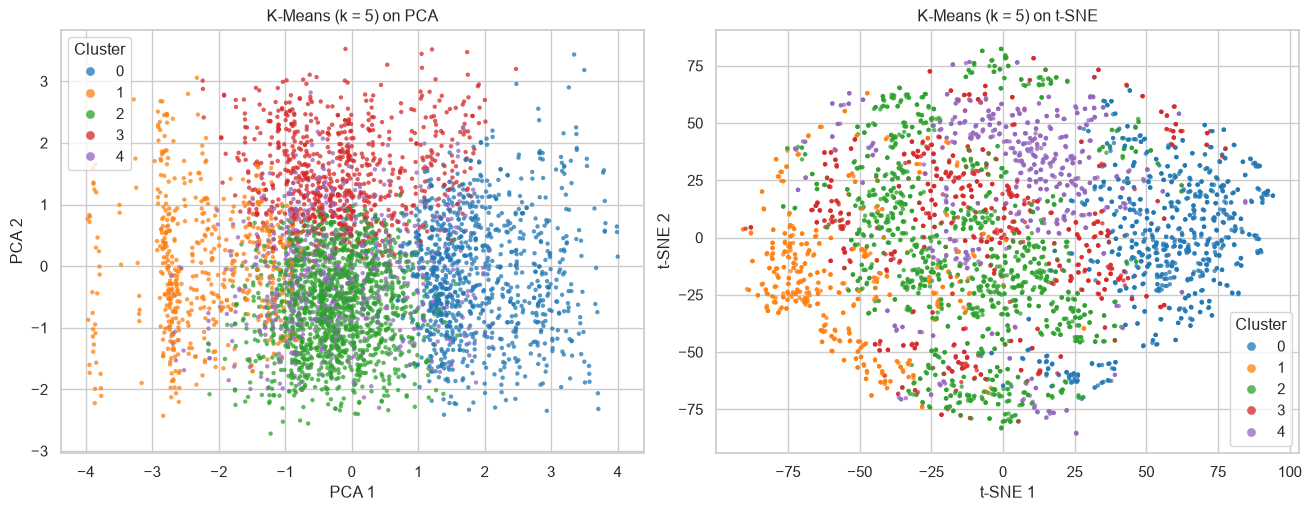

,KMeans,Ward,DBSCAN
EmployeeID,,,
1,1,4,0
2,2,4,0
3,4,2,-1
4,0,0,0
5,3,3,0


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for ax, xy, name in [(axes[0], X_pca[["PC1", "PC2"]].values, "PCA"),
                     (axes[1], X_tsne, "t-SNE")]:
    sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=labels["KMeans"].values,
                    palette="tab10", s=10, alpha=0.75, linewidth=0, ax=ax)
    ax.set(title=f"K-Means (k = {K_FINAL}) on {name}", xlabel=f"{name} 1", ylabel=f"{name} 2")
    ax.legend(title="Cluster", markerscale=2)
save(fig, "clusters_2d.png")

labels.to_csv("cluster_labels.csv")
labels.head()

# MODEL EVALUATION

The clustering models are evaluated from four angles:
1. **Internal validity** (Silhouette ↑, Davies–Bouldin ↓, Calinski–Harabasz ↑) against two **baselines**: random labels and K-Means on unscaled data.
2. **Stability**: are the K-Means clusters reproduced on bootstrap samples and with other random seeds?
3. **Sensitivity to the feature choice**: what happens when one feature group is removed?
4. **External validation**: do the clusters separate employees with different attrition rates, although `Attrition` was never used for training?

## Comparison with baselines

In [43]:
rng = np.random.default_rng(RANDOM_STATE)

# Baseline 1: random assignment into K_FINAL groups (mean of 20 draws)
rand_scores = pd.DataFrame([scores(A, rng.integers(0, K_FINAL, len(A))) for _ in range(20)]).mean()

# Baseline 2: K-Means on the raw (unscaled, untransformed) features, scored in the scaled space
lab_raw = KMeans(K_FINAL, n_init=10, random_state=RANDOM_STATE).fit_predict(X_raw)

is_core = labels["DBSCAN"].values != -1
eval_table = pd.DataFrame({
    "Baseline: random labels": {**rand_scores, "clusters": K_FINAL},
    "Baseline: K-Means, unscaled": {**scores(A, lab_raw), "clusters": K_FINAL},
    f"K-Means (k={K_FINAL})": {**scores(A, labels["KMeans"]), "clusters": K_FINAL},
    f"Ward (k={K_FINAL})": {**scores(A, labels["Ward"]), "clusters": K_FINAL},
    f"DBSCAN (eps={EPS})": {"silhouette": np.nan, "davies_bouldin": np.nan,
                            "calinski_harabasz": np.nan,
                            "clusters": len(set(labels["DBSCAN"]) - {-1})},
}).T
eval_table["clusters"] = eval_table["clusters"].astype(int)
print("Internal validity (all in the scaled 13-feature space):")
print(eval_table.round(3).to_string())

# Which feature dominates the unscaled K-Means? -> spread of each raw feature across its clusters
dom = (X_raw.groupby(lab_raw).mean().std() / X_raw.std()).sort_values(ascending=False)
print("\nUnscaled K-Means: between-cluster spread / overall std (top 3):")
print(dom.head(3).round(2).to_string())

Internal validity (all in the scaled 13-feature space):
                             silhouette  davies_bouldin  calinski_harabasz  clusters
Baseline: random labels          -0.007          52.404              0.990         5
Baseline: K-Means, unscaled       0.010           9.610             86.706         5
K-Means (k=5)                     0.082           2.666            310.869         5
Ward (k=5)                        0.047           3.240            218.631         5
DBSCAN (eps=3.0)                    NaN             NaN                NaN         1

Unscaled K-Means: between-cluster spread / overall std (top 3):
MonthlyIncome     1.31
JobLevel          0.10
BusinessTravel    0.10


**Interpretation.**
- K-Means and Ward clearly beat the **random baseline** (silhouette ≈ 0, Calinski–Harabasz ≈ 1), so the partitions capture real structure, even if weak.
- Without scaling, K-Means only cuts `MonthlyIncome` into bands (its between-cluster spread is far larger than for any other feature): in the scaled space this partition is barely better than random. Scaling is therefore essential. *(The earlier sanity check scored each matrix in its own space, which made the raw model look best at 0.708; it now scores every model in the same space.)*
- **K-Means is better than Ward on all three indices**; DBSCAN produces a single cluster and cannot be scored.
- The absolute values are low (silhouette 0.08): the 13 features contain weak group structure and the clusters are neighbouring regions of one cloud (see the PCA/t-SNE maps).

## Stability of the selected K-Means model

In [44]:
# (a) bootstrap: refit on a resample, label all employees, compare with the final model
ari_boot = []
for b in range(20):
    idx = rng.choice(len(A), len(A), replace=True)
    m = KMeans(K_FINAL, n_init=10, random_state=b).fit(A[idx])
    ari_boot.append(adjusted_rand_score(labels["KMeans"], m.predict(A)))

# (b) one random initialisation per run, 20 seeds
seed_labs = [KMeans(K_FINAL, n_init=1, random_state=s).fit_predict(A) for s in range(20)]
ari_seed = [adjusted_rand_score(seed_labs[i], seed_labs[j]) for i in range(20) for j in range(i + 1, 20)]

stab = pd.DataFrame({"mean ARI": [np.mean(ari_boot), np.mean(ari_seed), km_table.loc[K_FINAL, "stability_ARI"]],
                     "min ARI": [np.min(ari_boot), np.min(ari_seed), np.nan]},
                    index=["Bootstrap vs. final model (n_init=10)",
                           "Different seeds, n_init=1",
                           "80% subsamples, pairwise (model selection)"])
print(stab.round(3).to_string())

                                            mean ARI  min ARI
Bootstrap vs. final model (n_init=10)          0.801    0.496
Different seeds, n_init=1                      0.525    0.287
80% subsamples, pairwise (model selection)     0.816      NaN


**Interpretation.**
- With a single random initialisation K-Means often ends in a different local optimum (mean ARI ≈ 0.53), so many initialisations are required; the final model uses `n_init=20`.
- With 10 initialisations the partition is reproduced reasonably on bootstrap samples (mean ARI ≈ 0.80, similar to the 0.82 found on 80% subsamples during model selection), but the worst resample only reaches ≈ 0.50.
- The main segments are therefore stable, but the borders between neighbouring clusters are soft and individual assignments near a border should not be over-interpreted.

## Sensitivity to the feature groups

Each feature group is removed in turn and K-Means (k = 5) is refitted. If the silhouette rises and the partition barely changes (high ARI with the final model), the group adds little structure; if the partition changes a lot (low ARI), the group drives the segmentation.

In [45]:
abl_rows = []
for g, cols in FEATURE_GROUPS.items():
    keep = [f for f in FEATURES if f not in cols]
    lab = KMeans(K_FINAL, n_init=10, random_state=RANDOM_STATE).fit_predict(X[keep])
    abl_rows.append({"Removed group": g, "features left": len(keep),
                     "silhouette": silhouette_score(X[keep], lab),
                     "ARI vs final model": adjusted_rand_score(labels["KMeans"], lab)})
abl = pd.DataFrame(abl_rows).set_index("Removed group")
abl.loc["(none - final model)"] = [len(FEATURES), silhouette_score(A, labels["KMeans"]), 1.0]
print(abl.round(3).to_string())

                           features left  silhouette  ARI vs final model
Removed group                                                           
Seniority & pay                        8       0.121               0.267
Workload & attendance                 11       0.097               0.519
Satisfaction & engagement              9       0.125               0.895
Commute & travel                      11       0.094               0.507
(none - final model)                  13       0.082               1.000


**Interpretation.**
- Removing *Seniority & pay*, *Workload* or *Commute* changes the partition a lot (ARI ≈ 0.27–0.52): these three groups **drive** the segmentation.
- Removing the four *Satisfaction* scores leaves the partition almost unchanged (ARI ≈ 0.9) and *raises* the silhouette: the survey scores add noise rather than structure. This matches the EDA, where they are uncorrelated with every other variable. The satisfaction dimension is therefore studied in the profiles rather than expected to form its own segment.

## k = 3 vs k = 5
Model selection kept k = 5 but noted k = 3 as a close, more stable alternative. Both are compared on the internal indices, stability and their link with attrition.

In [46]:
from scipy.stats import chi2_contingency

def cramers_v(lab, y):
    chi2 = chi2_contingency(pd.crosstab(lab, y))[0]
    return np.sqrt(chi2 / len(y))           # y is binary -> min(r, c) - 1 = 1

k_rows = {}
for k in (3, 5):
    lab = KMeans(k, n_init=20, random_state=RANDOM_STATE).fit_predict(A)
    rates = df["Attrition"].groupby(lab).mean()
    k_rows[f"k = {k}"] = {**scores(A, lab),
                          "stability_ARI": km_table.loc[k, "stability_ARI"],
                          "Cramer_V_attrition": cramers_v(lab, df["Attrition"]),
                          "min attrition %": rates.min() * 100,
                          "max attrition %": rates.max() * 100,
                          "cluster sizes": sorted(np.bincount(lab).tolist(), reverse=True)}
pd.DataFrame(k_rows).T

,silhouette,davies_bouldin,calinski_harabasz,stability_ARI,Cramer_V_attrition,min attrition %,max attrition %,cluster sizes
k = 3,0.081367,3.045655,387.754641,0.851479,0.158786,11.40625,25.195618,"[1852, 1280, 1278]"
k = 5,0.081907,2.666252,310.869417,0.816373,0.254772,8.645337,37.05036,"[1469, 949, 740, 696, 556]"


**Interpretation.** k = 3 has a slightly better silhouette and Calinski–Harabasz value and is a little more stable, but its clusters only split tenure (attrition from 11% to 25%). With k = 5 the Davies–Bouldin index is clearly better, and the partition separates attrition much more sharply (8.6% to 37.1%, Cramér's V 0.26 instead of 0.16) because it also isolates the overtime and long-commute groups. Since the internal indices are almost tied, the better external validity and the more actionable segments justify k = 5.

## Effect of replicated records

`general_data.csv` has no duplicate rows *with* `EmployeeID`, but many rows are identical in every other column. The check below groups employees by all `general_data` attributes (except the ID) and measures how this affects the models.

In [47]:
gen_cols = [c for c in df_general.columns if c != "EmployeeID"]
profile_id = (df_general.set_index("EmployeeID")[gen_cols].fillna(-1)
              .groupby(gen_cols).ngroup().reindex(df.index).values)
group_size = pd.Series(profile_id).map(pd.Series(profile_id).value_counts())
print(f"Distinct general profiles: {len(np.unique(profile_id))} for {len(df)} employees")
print("Employees by size of their identical-profile group:",
      group_size.value_counts().sort_index().to_dict())
print("Profiles whose copies have different Attrition:",
      int((df['Attrition'].groupby(profile_id).nunique() > 1).sum()))

# How close are the copies in the clustering space? (they differ only in survey and attendance)
nn_idx = NearestNeighbors(n_neighbors=2).fit(A).kneighbors(A)[1][:, 1]
print(f"Nearest neighbour is a copy of the same profile: {(profile_id[nn_idx] == profile_id).mean():.1%}")
twin_d = [np.linalg.norm(A[ix[0]] - A[ix[1]])
          for ix in pd.Series(range(len(A))).groupby(profile_id).apply(list) if len(ix) > 1]
pair = rng.integers(0, len(A), (3000, 2))
print(f"Median distance between copies: {np.median(twin_d):.2f}  vs random pairs: "
      f"{np.median(np.linalg.norm(A[pair[:, 0]] - A[pair[:, 1]], axis=1)):.2f}")

# Refit on one copy per profile
first = pd.Series(range(len(A))).groupby(profile_id).first().values
A_dedup = A[first]
dup_rows = []
for eps in (2.6, 2.8, 3.0, 3.2):
    full = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(A)
    ded = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(A_dedup)
    dup_rows.append({"eps": eps, "noise % (all 4,410)": (full == -1).mean() * 100,
                     "noise % (one copy per profile)": (ded == -1).mean() * 100,
                     "clusters (dedup)": len(set(ded) - {-1})})
km_dedup = KMeans(K_FINAL, n_init=20, random_state=RANDOM_STATE).fit(A_dedup)
print(f"K-Means on one copy per profile: silhouette {silhouette_score(A_dedup, km_dedup.labels_):.3f}, "
      f"ARI with the final model {adjusted_rand_score(labels['KMeans'], km_dedup.predict(A)):.3f}")
pd.DataFrame(dup_rows).set_index("eps").round(1)

Distinct general profiles: 1498 for 4410 employees
Employees by size of their identical-profile group: {1: 28, 2: 56, 3: 4326}
Profiles whose copies have different Attrition: 0
Nearest neighbour is a copy of the same profile: 92.2%
Median distance between copies: 1.09  vs random pairs: 4.93


K-Means on one copy per profile: silhouette 0.076, ARI with the final model 0.511


,"noise % (all 4,410)",noise % (one copy per profile),clusters (dedup)
eps,,,
2.6,21.0,48.8,1
2.8,7.9,26.2,1
3.0,2.4,10.1,1
3.2,0.7,3.3,1


**Interpretation.**
- The 4,410 employees come from only about **1,500 distinct general profiles**; most profiles appear **three times** with a different `EmployeeID`, survey answers and attendance log, but always with the same `Attrition`. The Kaggle file was evidently built by replicating a smaller HR table.
- In the clustering space the copies sit very close together: for about nine employees in ten the nearest neighbour is a copy of themselves, about 4–5 times closer than a random pair.
- **Effect on DBSCAN:** every point automatically has two very close neighbours, so local density is artificially high. With one copy per profile the same `eps` labels 2–5 times more employees as noise (e.g. 10.1% instead of 2.4% at `eps = 3.0`). The `eps = 3.0` chosen on the full data is therefore optimistic, and DBSCAN still finds a single cluster — the replication does not create a cluster structure, it only hides sparse regions.
- **Effect on K-Means:** the silhouette barely changes, but the partition is only partly reproduced (moderate ARI): with a third of the data the borders move, as expected for soft clusters.
- **Effect on statistical tests:** the effective sample is about 1,500 independent profiles rather than 4,410, so p-values (EDA tests, chi-square) are smaller than they should be. The conclusions do not change because the effects are very large, but the exact p-values should be read with caution.
- The records were **kept**: each copy has its own survey and attendance data, and removing them would discard real information in those files.

# CLUSTER PROFILING

Each K-Means cluster is described by the mean of the clustering features and of variables **not** used for training (age, number of previous employers, attrition). Names are assigned from the profile with explicit rules, so they stay correct if the cluster numbers change.

In [48]:
seg = df.copy()
seg["Cluster"] = labels["KMeans"].values

PROFILE_COLS = FEATURES + ["Age", "NumCompaniesWorked", "YearsWithCurrManager"]
profile = seg.groupby("Cluster")[PROFILE_COLS + ["Attrition"]].mean()
profile.insert(0, "Size", seg["Cluster"].value_counts().sort_index())
profile.insert(1, "Share %", profile["Size"] / len(seg) * 100)

# Naming rules (each rule picks among the clusters not named yet)
names, rest = {}, list(profile.index)
def pick(col, how, name):
    c = profile.loc[rest, col].idxmin() if how == "min" else profile.loc[rest, col].idxmax()
    names[c] = name; rest.remove(c)
pick("TotalWorkingYears", "min", "Newcomers")
pick("YearsSinceLastPromotion", "max", "Stagnant veterans")
pick("AvgWorkHours", "max", "Overtime workers")
pick("DistanceFromHome", "max", "Long commuters")
names[rest[0]] = "Steady core"
seg["Segment"] = seg["Cluster"].map(names)
profile.insert(0, "Segment", profile.index.map(names))
profile.round(2).T

Cluster,0,1,2,3,4
Segment,Stagnant veterans,Newcomers,Steady core,Overtime workers,Long commuters
Size,949,556,1469,740,696
Share %,21.52,12.61,33.31,16.78,15.78
MonthlyIncome,71796.62,67015.59,64157.83,59727.12,61692.08
JobLevel,1.87,1.93,2.2,2.23,1.97
TotalWorkingYears,17.93,2.54,10.96,11.3,9.83
YearsAtCompany,14.39,1.27,5.58,6.07,5.55
YearsSinceLastPromotion,6.96,0.42,0.7,1.35,1.14
AvgWorkHours,7.42,7.67,7.03,9.74,7.35
AbsentRate,0.05,0.05,0.06,0.04,0.05


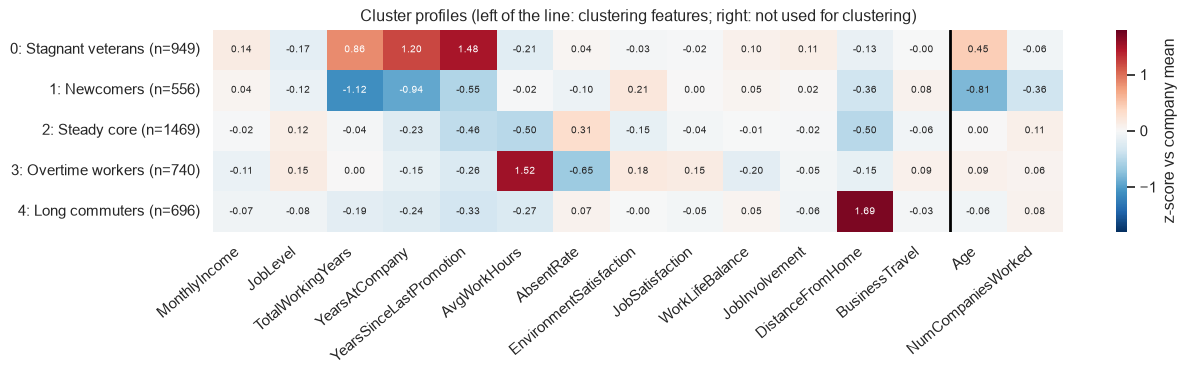

In [49]:
# Heatmap of standardised means (z-score of each cluster mean vs. company mean)
Z_COLS = FEATURES + ["Age", "NumCompaniesWorked"]
zprof = (seg.groupby("Cluster")[Z_COLS].mean() - seg[Z_COLS].mean()) / seg[Z_COLS].std()
zprof.index = [f"{c}: {names[c]} (n={profile.loc[c, 'Size']})" for c in zprof.index]

fig, ax = plt.subplots(figsize=(13, 3.9))
sns.heatmap(zprof, cmap="RdBu_r", center=0, vmin=-1.8, vmax=1.8, annot=True, fmt=".2f",
            annot_kws={"size": 7}, cbar_kws={"label": "z-score vs company mean"}, ax=ax)
ax.axvline(len(FEATURES), color="black", lw=2)
ax.set_title("Cluster profiles (left of the line: clustering features; right: not used for clustering)")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
save(fig, "eval_profile_heatmap.png")

In [50]:
# Composition by nominal variables that were NOT used for clustering
for col in ["MaritalStatus", "Department"]:
    tab = pd.crosstab(seg["Segment"], seg[col], normalize="index") * 100
    print(f"{col} (% of each segment):")
    print(tab.round(1).to_string(), "\n")

MaritalStatus (% of each segment):
MaritalStatus      Divorced  Married  Single
Segment                                     
Long commuters         23.0     47.3    29.7
Newcomers              15.5     38.3    46.2
Overtime workers       25.9     44.7    29.3
Stagnant veterans      19.6     53.1    27.3
Steady core            24.3     43.7    32.0 

Department (% of each segment):
Department         Human Resources  Research & Development  Sales
Segment                                                          
Long commuters                 3.2                    65.2   31.6
Newcomers                      4.5                    63.1   32.4
Overtime workers               4.6                    66.4   29.1
Stagnant veterans              3.1                    67.1   29.8
Steady core                    5.4                    64.7   30.0 



# EXTERNAL VALIDATION WITH ATTRITION

In [51]:
from scipy.stats import chi2_contingency

def attrition_test(lab):
    ct = pd.crosstab(lab, seg["Attrition"])
    chi2, p, dof, _ = chi2_contingency(ct)
    return chi2, p, np.sqrt(chi2 / (len(seg) * (min(ct.shape) - 1)))

ext = pd.DataFrame(
    {name: dict(zip(["chi2", "p_value", "Cramer_V"], attrition_test(lab)))
     for name, lab in [(f"K-Means (k={K_FINAL})", labels["KMeans"].values),
                       (f"Ward (k={K_FINAL})", labels["Ward"].values),
                       ("DBSCAN anomaly vs rest", labels["DBSCAN"].values == -1),
                       ("Random labels", rng.integers(0, K_FINAL, len(seg)))]}).T
print("Association between cluster labels and Attrition:")
print(ext.to_string(formatters={"chi2": "{:.1f}".format, "p_value": "{:.1e}".format,
                                "Cramer_V": "{:.3f}".format}))

Association between cluster labels and Attrition:
                        chi2 p_value Cramer_V
K-Means (k=5)          286.2 1.0e-60    0.255
Ward (k=5)             107.0 3.2e-22    0.156
DBSCAN anomaly vs rest  30.5 3.3e-08    0.083
Random labels            1.9 7.5e-01    0.021


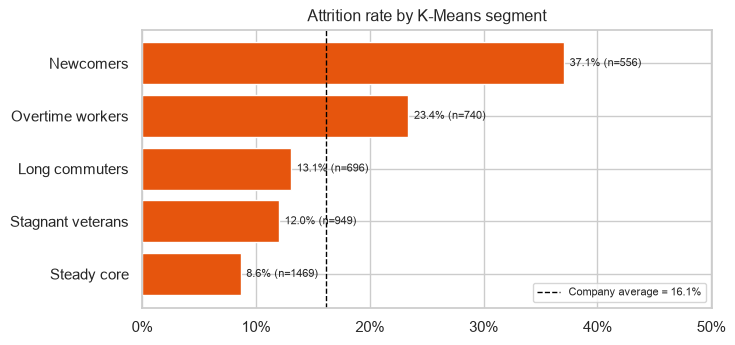

,Attrition rate,Leavers,Employees,Share of workforce,Share of leavers,Lift
Segment,,,,,,
Newcomers,0.371,206,556,0.126,0.290,2.298
Overtime workers,0.234,173,740,0.168,0.243,1.450
Long commuters,0.131,91,696,0.158,0.128,0.811
Stagnant veterans,0.120,114,949,0.215,0.160,0.745
Steady core,0.086,127,1469,0.333,0.179,0.536


In [52]:
overall = seg["Attrition"].mean()
rate = (seg.groupby("Segment")["Attrition"].agg(["mean", "sum", "count"])
        .rename(columns={"mean": "Attrition rate", "sum": "Leavers", "count": "Employees"}))
rate["Share of workforce"] = rate["Employees"] / len(seg)
rate["Share of leavers"] = rate["Leavers"] / rate["Leavers"].sum()
rate["Lift"] = rate["Attrition rate"] / overall
rate = rate.sort_values("Attrition rate", ascending=False)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
bars = ax.barh(rate.index[::-1], rate["Attrition rate"][::-1], color="#e6550d")
ax.axvline(overall, color="black", ls="--", lw=1, label=f"Company average = {overall:.1%}")
for b, (v, n) in zip(bars, rate[["Attrition rate", "Employees"]].values[::-1]):
    ax.text(v + 0.005, b.get_y() + b.get_height() / 2, f"{v:.1%} (n={int(n)})", va="center", fontsize=8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlim(0, rate["Attrition rate"].max() * 1.35)
ax.set_title("Attrition rate by K-Means segment")
ax.legend(fontsize=8, loc="lower right")
save(fig, "eval_attrition.png")
rate.round(3)

**Interpretation.**
- The K-Means segments are strongly associated with attrition (p far below 0.001), while random labels show no association. `Attrition` was never used for training, so this is independent evidence that the segments are meaningful.
- K-Means separates attrition better than Ward (higher Cramér's V), which agrees with the internal indices.
- **Newcomers** (≈2.5 working years, ≈1.3 years at the company, ≈29 years old, 46% single) have an attrition rate of ≈37%, about 2.3× the company average.
- **Overtime workers** (≈9.7 hours per day, the fewest absences) have ≈23% attrition, about 1.5× the average – a burnout signal: their job and environment satisfaction is *not* lower, only work-life balance is slightly lower, so surveys alone would miss this group.
- **Stagnant veterans** (≈14 years at the company, ≈7 years since the last promotion), **Long commuters** (≈23 km from home) and the **Steady core** (≈7 hours per day, close to the office) are below the average; the Steady core is the most stable group (≈9%).
- Satisfaction scores differ only slightly between segments (|z| ≤ 0.21), consistent with the sensitivity analysis.

### Cluster × Attrition matrix
For clustering there is no predicted label, so a classic confusion matrix cannot be computed. The closest equivalent is the contingency matrix between the clusters and the true `Attrition` label: counts on the left and the share of leavers/stayers inside each cluster on the right.

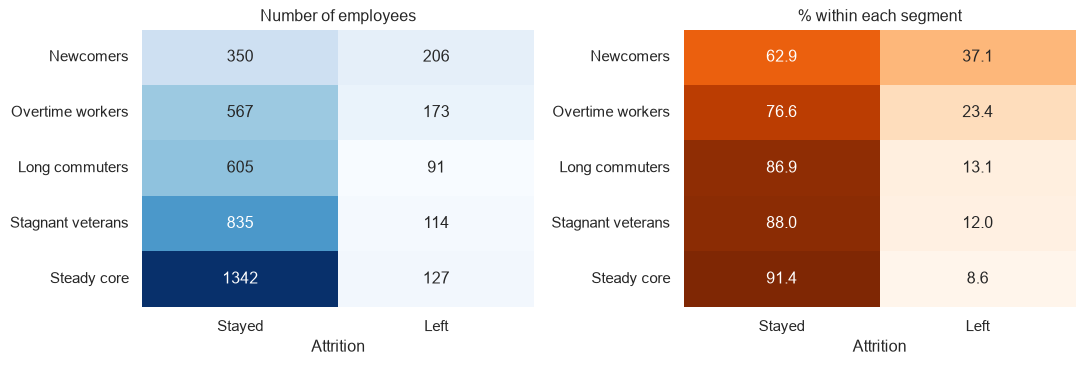

Attrition,Stayed,Left,Left %
Segment,,,
Newcomers,350,206,37.1
Overtime workers,567,173,23.4
Long commuters,605,91,13.1
Stagnant veterans,835,114,12.0
Steady core,1342,127,8.6


In [53]:
ct_counts = pd.crosstab(seg["Segment"], seg["Attrition"].map({0: "Stayed", 1: "Left"}))[["Stayed", "Left"]]
ct_counts = ct_counts.loc[rate.index]                      # same order as the bar chart
ct_row = ct_counts.div(ct_counts.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.heatmap(ct_counts, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set(title="Number of employees", xlabel="Attrition", ylabel="")
sns.heatmap(ct_row, annot=True, fmt=".1f", cmap="Oranges", cbar=False, ax=axes[1])
axes[1].set(title="% within each segment", xlabel="Attrition", ylabel="")
save(fig, "eval_attrition_matrix.png")
ct_counts.assign(**{"Left %": ct_row["Left"].round(1)})

**Interpretation.** Read row by row: in the *Newcomers* row 206 of 556 employees left (37.1%), in the *Steady core* only 127 of 1,469 (8.6%). The left column shows that the leavers are not spread evenly: two segments (Newcomers and Overtime workers) contain 379 of the 711 leavers. A partition with no link to attrition would show about 16% in every row, as in the random baseline.

## Agreement between K-Means and Ward

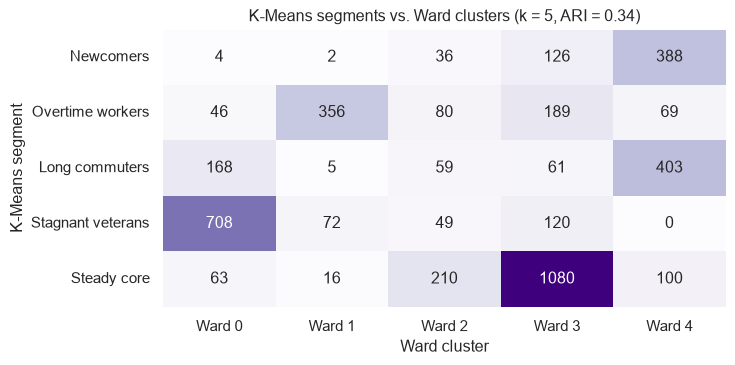

Segment
Newcomers            69.8
Overtime workers     48.1
Long commuters       57.9
Stagnant veterans    74.6
Steady core          73.5
Name: % in best-matching Ward cluster, dtype: float64

In [54]:
km_ward = pd.crosstab(seg["Segment"], labels["Ward"].values)
km_ward.columns = [f"Ward {c}" for c in km_ward.columns]
km_ward = km_ward.loc[rate.index]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
sns.heatmap(km_ward, annot=True, fmt="d", cmap="Purples", cbar=False, ax=ax)
ax.set(title=f"K-Means segments vs. Ward clusters (k = {K_FINAL}, ARI = {ari_km_ward:.2f})",
       xlabel="Ward cluster", ylabel="K-Means segment")
save(fig, "eval_km_vs_ward.png")

# For each K-Means segment: share of its members that fall into its best-matching Ward cluster
(km_ward.max(axis=1) / km_ward.sum(axis=1) * 100).round(1).rename("% in best-matching Ward cluster")

**Interpretation.** The two algorithms agree on the core of most segments: about three quarters of the *Stagnant veterans* and of the *Steady core*, and 70% of the *Newcomers*, fall into a single Ward cluster. They disagree in two places: Ward puts the *Newcomers* and most *Long commuters* into the **same** cluster (it does not separate distance from low tenure), and it spreads the *Overtime workers* over several clusters (only 48% in the best match). This explains the moderate ARI (0.34): the main structure is found by both methods, but where the data is a continuous cloud they draw different borders. The K-Means version is preferred because it separates attrition better (Cramér's V 0.26 vs 0.16).

# CONCLUSION

**Summary.** Five relational files describing 4,410 employees were merged and cleaned; attendance logs were converted into working-hour and absence features. Thirteen features covering seniority & pay, workload, satisfaction and commute were log-transformed (skewed ones), standardised and clustered with K-Means, Ward hierarchical clustering and DBSCAN.

**Best model.** **K-Means with k = 5** is the best model: it beats Ward on all internal indices, beats the random and unscaled baselines, is reproducible under bootstrap resampling, and separates attrition better than Ward. DBSCAN finds no segmentation in this continuous data but is useful as an anomaly detector (2.4% of employees, mostly high-level employees working long hours with poor work-life balance, 36% attrition).

**Practical implications for HR.** The segments tell HR *where* to act first and *what kind* of action fits each group.

| Segment | What the data shows | Why it matters | Recommended actions |
|---|---|---|---|
| **Newcomers** (12.6%) | ≈2.5 years of experience, ≈1.3 years here, 37% leave (2.3× average); they are 13% of staff but 29% of all leavers | Every early leaver wastes the hiring and training cost and the gap must be filled again | Structured onboarding with a named mentor; check-in meetings at 3, 6 and 12 months; a visible path to the first promotion within two years; exit interviews to learn why they leave |
| **Overtime workers** (16.8%) | ≈9.7 hours per day (2 hours more than average), the fewest absences, 23% leave (1.45× average); satisfaction scores are *not* lower | A burnout risk that an engagement survey would not detect, so it must be tracked from attendance data | Monthly report of average working hours per team; alert when an employee exceeds ~9 hours per day for several weeks; redistribute workload or hire; give compensatory time off |
| **Stagnant veterans** (21.5%) | ≈14 years here, ≈7 years without promotion, highest pay, 12% leave | Low attrition today, but they hold critical knowledge; long stagnation can turn into disengagement | Career conversations; expert / specialist tracks that do not require a management post; job rotation; involve them as mentors for newcomers |
| **Long commuters** (15.8%) | ≈23 km from home, otherwise average, 13% leave | Not a priority risk now, but commuting adds daily fatigue | Flexible hours or partial remote work; transport allowance; consider commute when assigning shifts |
| **Steady core** (33.3%) | ≈7 hours per day, close to the office, recently promoted, 9% leave | The most stable group; useful as a benchmark of healthy conditions | Maintain current conditions; use as a reference group when evaluating HR policies |

**How to use the segmentation in practice.** (1) Assign each new or existing employee to a segment with the fitted scaler and K-Means model; (2) focus retention budgets on the two high-risk segments, which together contain 53% of all leavers while representing only 29% of the workforce; (3) review the 105 DBSCAN anomalies individually, because they combine long hours, poor work-life balance and a 36% attrition rate; (4) re-run the clustering every year to see whether employees move between segments after the actions above.

**Limitations.**
- The cluster structure is weak (silhouette ≈ 0.08): segments are soft regions of one continuous cloud, and employees near a border could belong to a neighbouring segment.
- The satisfaction scores add no structure (removing them barely changes the partition), so the segmentation cannot describe satisfaction-based groups.
- The dataset is semi-synthetic (many replicated records; several attributes behave like independent random values), attendance covers only 2015, and K-Means assumes roughly spherical clusters.

**Future work.** Test Gaussian Mixture Models (soft membership) or K-Prototypes (numeric and categorical features together), validate the segments on real HR data, and combine them with a supervised attrition model to target retention actions.